# Chapter 15: Language Models and the Transformer (PyTorch Edition)

This notebook is a **full PyTorch conversion** of the companion notebook for [Deep Learning with Python, Third Edition](https://www.manning.com/books/deep-learning-with-python-third-edition), with **mechanistic interpretability** analysis inspired by recent advances in transformer interpretability research.

**Style follows** the Chapter 10 ConvNet interpretability notebook — extensively detailed inline comments, rich visualizations, and pedagogical explanations.

## What You'll Learn

| Section | Technique | Key Idea |
|---|---|---|
| **GRU Language Model** | Character-level language model | Recurrent hidden state h_t = GRU(x_t, h_{t-1}) |
| **Hidden State Dynamics** | Activation heatmaps & PCA trajectories | What the GRU remembers |
| **Seq2Seq RNN** | Encoder-Decoder translation | Information bottleneck |
| **Scaled Dot-Product Attention** | Attention weight visualization | Q·K^T / √d_k |
| **Transformer Encoder/Decoder** | Multi-head attention blocks | Residual stream analysis |
| **Positional Encoding** | Sinusoidal vs Learned | Geometric structure of position |
| **Attention Head Visualization** | Head specialization & rollout | Mechanistic interpretability |
| **Logit Lens** | Layer-by-layer prediction evolution | Residual stream decoding |
| **Probing Classifiers** | What each layer encodes | Linear probes on hidden states |
| **Fine-tuning RoBERTa** | Pretrained transformer for IMDb | Transfer learning |
| **Head Ablation** | Task-relevant head identification | Gradient-weighted attention |

---


---
## 0. Setup & Imports

Install and import all required libraries. Configure device selection (CUDA > MPS > CPU). Define global helpers.


In [1]:
# ============================================================
# CELL 0 — Install dependencies (run once)
# ============================================================
# Uncomment the lines below if packages are not yet installed:
# !pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu -q
# !pip install transformers datasets sacrebleu seaborn scikit-learn -q

# ============================================================
# IMPORTS — All libraries needed throughout this notebook
# ============================================================

# --- Core Python ---
import os, re, math, random, json, string, pathlib, warnings, time
from collections import Counter
from io import BytesIO

warnings.filterwarnings("ignore")   # Suppress non-critical warnings

# --- PyTorch core ---
import torch                           # Main PyTorch library
import torch.nn as nn                  # Neural network building blocks
import torch.nn.functional as F        # Stateless operations (softmax, relu, etc.)
from torch.utils.data import Dataset, DataLoader, Subset  # Data utilities

# --- Numerical & visualization ---
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# --- NLP utilities ---
# torchtext may not be installed; we fall back to a custom vocab class
try:
    from torchtext.vocab import build_vocab_from_iterator
    TORCHTEXT_AVAILABLE = True
except ImportError:
    TORCHTEXT_AVAILABLE = False
    print("torchtext not found — using custom Vocab class")

# --- HuggingFace (for RoBERTa section) ---
try:
    from transformers import (
        RobertaTokenizerFast, RobertaModel,
        AdamW, get_linear_schedule_with_warmup,
    )
    HF_AVAILABLE = True
except ImportError:
    HF_AVAILABLE = False
    print("transformers not found — RoBERTa section will be skipped")

# ============================================================
# DEVICE SELECTION — Priority: CUDA GPU > Apple MPS > CPU
# ============================================================
device = torch.device(
    "cuda" if torch.cuda.is_available() else
    "mps"  if torch.backends.mps.is_available() else
    "cpu"
)
print(f"✅ Using device: {device}")

# ============================================================
# GLOBAL HELPER UTILITIES
# ============================================================

def set_seed(seed: int = 42):
    """Fix all random seeds for reproducibility across Python, NumPy, and PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    print(f"   Random seed set to {seed}")

def count_parameters(model: nn.Module) -> int:
    """Count and print trainable parameters in a model, broken down by sub-module."""
    total = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\n{'Layer':<40} {'Params':>12}")
    print("-" * 54)
    for name, module in model.named_children():
        n = sum(p.numel() for p in module.parameters() if p.requires_grad)
        print(f"  {name:<38} {n:>12,}")
    print("-" * 54)
    print(f"  {'TOTAL':<38} {total:>12,}")
    return total

def plot_training_curves(train_losses, val_losses=None, metric_name="Loss"):
    """Plot training (and optionally validation) curves side by side with loss and perplexity."""
    epochs = range(1, len(train_losses) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # LEFT: Raw loss
    axes[0].plot(epochs, train_losses, 'b-o', ms=4, label="Train")
    if val_losses:
        axes[0].plot(epochs, val_losses, 'r--s', ms=4, label="Val")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel(metric_name)
    axes[0].set_title(f"Training {metric_name}", fontweight='bold')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    # RIGHT: Perplexity = exp(loss) — a more intuitive NLP metric
    # PPL = 2 → model is only choosing between 2 tokens at each step
    # PPL = vocab_size → model is totally random
    train_ppl = [math.exp(min(l, 20)) for l in train_losses]
    axes[1].plot(epochs, train_ppl, 'b-o', ms=4, label="Train PPL")
    if val_losses:
        val_ppl = [math.exp(min(l, 20)) for l in val_losses]
        axes[1].plot(epochs, val_ppl, 'r--s', ms=4, label="Val PPL")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Perplexity")
    axes[1].set_title("Perplexity  $PPL = e^{\\mathcal{L}}$", fontweight='bold')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.tight_layout(); plt.show()

set_seed(42)
print(f"\nTorch version: {torch.__version__}")


torchtext not found — using custom Vocab class
transformers not found — RoBERTa section will be skipped
✅ Using device: mps
   Random seed set to 42

Torch version: 2.8.0


---
## 1. Character-Level Language Model: Shakespeare Dataset

We train a **character-level GRU** to model Shakespeare's writing. The model learns the distribution $P(c_t \mid c_1, \ldots, c_{t-1})$ over the next character given all previous characters.

### Architecture Overview

```
Input chars  →  Embedding  →  GRU  →  Dropout  →  Linear  →  Softmax
  (seq_len,)    (seq_len, E)  (seq_len, H)           (seq_len, vocab)
```

**Key recurrence equation:**

$$h_t = \text{GRU}(x_t, h_{t-1}) = (1-z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t$$

where $z_t$ is the update gate and $\tilde{h}_t$ is the candidate hidden state.


  Done.
Total characters: 1,115,394

First 250 characters:
--------------------------------------------------
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

--------------------------------------------------

Vocabulary size: 65
Characters: 
 !$&',-.3:;?ABCDEFGHIJKLMNOPQ ...


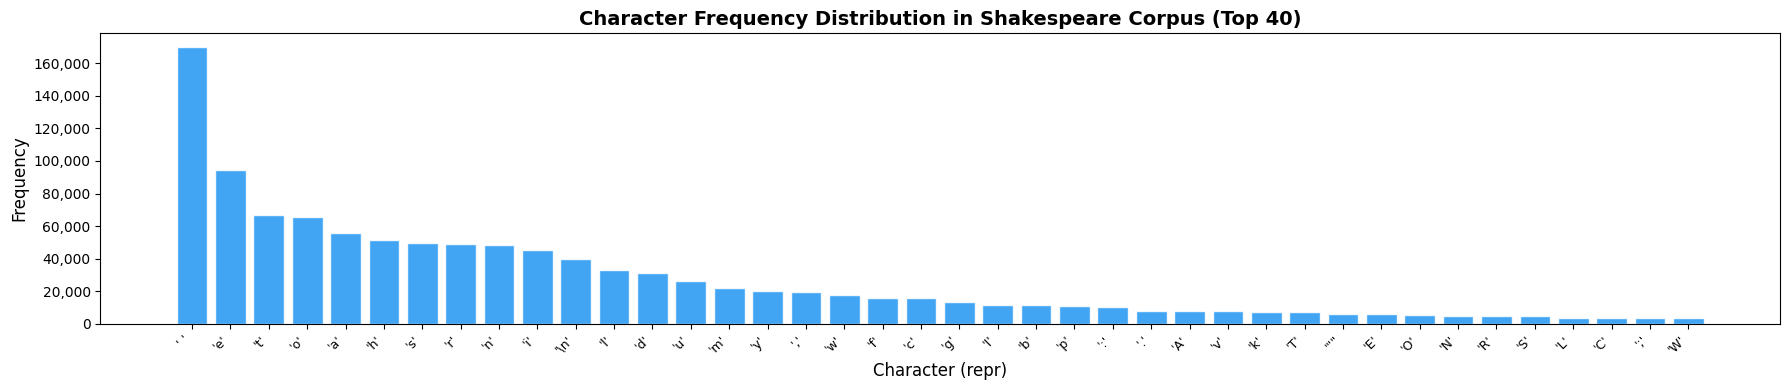

In [2]:
# ============================================================
# SECTION 1 — Download and inspect the Shakespeare corpus
# ============================================================
import urllib.request

SHAKESPEARE_URL = (
    "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt"
)
SHAKESPEARE_PATH = "shakespeare.txt"

# Download if not already cached
if not os.path.exists(SHAKESPEARE_PATH):
    print("Downloading Shakespeare corpus...")
    urllib.request.urlretrieve(SHAKESPEARE_URL, SHAKESPEARE_PATH)
    print("  Done.")

shakespeare = open(SHAKESPEARE_PATH, "r").read()
print(f"Total characters: {len(shakespeare):,}")
print(f"\nFirst 250 characters:\n{'-'*50}")
print(shakespeare[:250])
print(f"{'-'*50}")

# ============================================================
# CHARACTER VOCABULARY
# ============================================================
# We treat each unique character as a "token".
# A vocabulary of ~65 characters is far simpler than word-level (~50k tokens).

unique_chars = sorted(set(shakespeare))     # Sorted list of all unique chars
vocabulary_size = len(unique_chars)         # Typically ~65 for Shakespeare

# Create bidirectional lookup dictionaries
char_to_id = {ch: idx for idx, ch in enumerate(unique_chars)}  # e.g., 'A' → 13
id_to_char = {idx: ch for ch, idx in char_to_id.items()}        # e.g., 13 → 'A'

print(f"\nVocabulary size: {vocabulary_size}")
print(f"Characters: {''.join(unique_chars[:30])} ...")

# ============================================================
# VISUALIZE CHARACTER FREQUENCY DISTRIBUTION
# ============================================================
char_counts = Counter(shakespeare)
# Sort by frequency (descending) for the bar chart
sorted_chars = sorted(char_counts.items(), key=lambda x: -x[1])
chars_display = [repr(c[0]) for c in sorted_chars[:40]]   # repr() shows '\n' instead of a newline
counts_display = [c[1] for c in sorted_chars[:40]]

fig, ax = plt.subplots(figsize=(18, 4))
bars = ax.bar(range(40), counts_display, color='#2196F3', edgecolor='white', alpha=0.85)
ax.set_xticks(range(40))
ax.set_xticklabels(chars_display, rotation=45, ha='right', fontsize=9)
ax.set_xlabel("Character (repr)", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)
ax.set_title("Character Frequency Distribution in Shakespeare Corpus (Top 40)", fontsize=14, fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout(); plt.show()


In [3]:
# ============================================================
# SECTION 2 — Build the PyTorch Dataset and DataLoader
# ============================================================

sequence_length = 100   # Length of each input/target sequence (in characters)

class ShakespeareDataset(Dataset):
    """
    Character-level language model dataset from the Shakespeare corpus.

    Each sample is a (input_ids, target_ids) pair where:
      - input_ids  = chars at positions [i : i+seq_len]      (what the model sees)
      - target_ids = chars at positions [i+1 : i+seq_len+1]  (what it should predict)

    This "next-character prediction" formulation is the standard language modeling objective.
    The model learns P(c_{t+1} | c_1, ..., c_t) for every position t simultaneously.

    Args:
        text (str):          The raw text corpus.
        char_to_id (dict):   Character → integer token ID mapping.
        seq_len (int):       Length of each sequence window.
        stride (int):        Step between consecutive windows (default=1 = fully overlapping).
    """

    def __init__(self, text: str, char_to_id: dict, seq_len: int = 100, stride: int = 3):
        self.seq_len = seq_len
        self.char_to_id = char_to_id

        # Encode the entire text as a list of integer token IDs
        self.encoded = [char_to_id[c] for c in text]

        # Pre-compute all valid starting indices for the sliding window
        # We need at least seq_len+1 characters from each start position
        self.indices = list(range(0, len(self.encoded) - seq_len, stride))

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        start = self.indices[idx]
        # Input: characters [start : start+seq_len]
        # Target: characters [start+1 : start+seq_len+1]  (shifted by one position)
        x = torch.tensor(self.encoded[start : start + self.seq_len], dtype=torch.long)
        y = torch.tensor(self.encoded[start + 1 : start + self.seq_len + 1], dtype=torch.long)
        return x, y


# --- Instantiate dataset and dataloader ---
dataset = ShakespeareDataset(shakespeare, char_to_id, seq_len=sequence_length, stride=3)
dataloader = DataLoader(
    dataset,
    batch_size=64,       # Process 64 sequences at once
    shuffle=True,        # Shuffle for stochastic gradient descent
    num_workers=0,       # No multiprocessing (safe for notebooks)
    pin_memory=(device.type == 'cuda'),  # Faster host→GPU transfers
)

print(f"Dataset size:    {len(dataset):,} sequences")
print(f"Batches/epoch:   {len(dataloader):,}")

# --- Verify a single batch ---
x_batch, y_batch = next(iter(dataloader))
print(f"\nBatch x shape:   {x_batch.shape}   (batch_size × seq_len)")
print(f"Batch y shape:   {y_batch.shape}   (batch_size × seq_len)")
print(f"\nSample x[:20]:   {''.join([id_to_char[i.item()] for i in x_batch[0, :20]])!r}")
print(f"Sample y[:20]:   {''.join([id_to_char[i.item()] for i in y_batch[0, :20]])!r}")
print("Notice: y is x shifted by 1 character — the target is always the 'next' character")


Dataset size:    371,765 sequences
Batches/epoch:   5,809

Batch x shape:   torch.Size([64, 100])   (batch_size × seq_len)
Batch y shape:   torch.Size([64, 100])   (batch_size × seq_len)

Sample x[:20]:   ' threw caps up will '
Sample y[:20]:   'threw caps up will h'
Notice: y is x shifted by 1 character — the target is always the 'next' character


---
## 2. GRU Language Model: Architecture & Training

### Architecture Diagram

```
Token IDs  ──►  Embedding(vocab, E)  ──►  GRU(E→H)  ──►  Dropout  ──►  Linear(H→vocab)
  (B, T)          (B, T, E)               (B, T, H)       (B, T, H)       (B, T, vocab)
```

The GRU update equations at each timestep $t$:

$$z_t = \sigma(W_z x_t + U_z h_{t-1} + b_z)  \quad \text{(update gate)}$$
$$r_t = \sigma(W_r x_t + U_r h_{t-1} + b_r)  \quad \text{(reset gate)}$$
$$\tilde{h}_t = \tanh(W_h x_t + U_h (r_t \odot h_{t-1}) + b_h)  \quad \text{(candidate state)}$$
$$h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t  \quad \text{(new hidden state)}$$


GRU Language Model Architecture:
GRULanguageModel(
  (embedding): Embedding(65, 256)
  (gru): GRU(256, 512, batch_first=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (fc): Linear(in_features=512, out_features=65, bias=True)
)


Layer                                          Params
------------------------------------------------------
  embedding                                    16,640
  gru                                       1,182,720
  dropout                                           0
  fc                                           33,345
------------------------------------------------------
  TOTAL                                     1,232,705


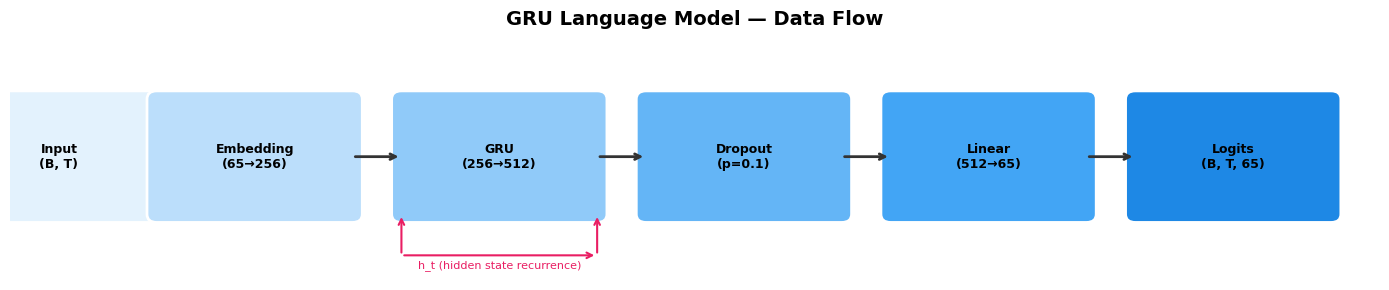

In [4]:
# ============================================================
# SECTION 3 — GRU Language Model Definition
# ============================================================

class GRULanguageModel(nn.Module):
    """
    Character-level language model using a Gated Recurrent Unit (GRU).

    Architecture:
        1. Embedding layer:  maps token IDs → dense vectors of size embedding_dim
        2. GRU layer:        processes the sequence and produces contextual hidden states
        3. Dropout layer:    regularizes by randomly zeroing hidden units during training
        4. Linear layer:     projects hidden states → vocabulary logits (unnormalized scores)

    During inference (generation), we call forward() one token at a time and pass
    the hidden state h from step t to step t+1 to maintain context.

    Args:
        vocab_size (int):     Number of unique characters.
        embedding_dim (int):  Size of the character embedding vectors.
        hidden_dim (int):     Size of the GRU hidden state.
        dropout (float):      Dropout probability applied to GRU output.
    """

    def __init__(self, vocab_size: int, embedding_dim: int = 256,
                 hidden_dim: int = 512, dropout: float = 0.1):
        super().__init__()
        self.hidden_dim = hidden_dim

        # EMBEDDING: converts token integer IDs → continuous dense vectors
        # Shape: (vocab_size, embedding_dim)
        # Think of it as a lookup table — each row is a learned character representation
        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        # GRU: the recurrent core of the model
        # batch_first=True → input/output shapes are (batch, seq, features)
        #                     instead of PyTorch's default (seq, batch, features)
        self.gru = nn.GRU(
            input_size=embedding_dim,   # Input feature dim (embedding size)
            hidden_size=hidden_dim,     # Hidden state dimension H
            batch_first=True,           # Expect input as (B, T, E)
        )

        # DROPOUT: randomly zeros a fraction of neurons to prevent overfitting
        # Only active during training (model.train()); disabled during model.eval()
        self.dropout = nn.Dropout(dropout)

        # LINEAR head: projects H-dimensional hidden state → vocab-sized logit vector
        # These logits are passed to softmax to get next-token probabilities
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x, h=None):
        """
        Forward pass through the language model.

        Args:
            x (Tensor):         Input token IDs, shape (batch_size, seq_len).
            h (Tensor or None): Initial hidden state, shape (1, batch_size, hidden_dim).
                                If None, GRU initializes to all-zeros.

        Returns:
            logits (Tensor):    Unnormalized scores, shape (batch_size, seq_len, vocab_size).
            h (Tensor):         Final hidden state, shape (1, batch_size, hidden_dim).
                                Pass this to the next call for autoregressive generation.
        """
        # Step 1: Embed — (B, T) → (B, T, E)
        embedded = self.embedding(x)

        # Step 2: GRU — (B, T, E) → output: (B, T, H), h_n: (1, B, H)
        # output[b, t, :] = hidden state at position t for batch element b
        # h_n is the final hidden state (equivalent to output[:, -1, :] for single-layer GRU)
        output, h = self.gru(embedded, h)

        # Step 3: Dropout on GRU output
        output = self.dropout(output)

        # Step 4: Linear projection — (B, T, H) → (B, T, vocab_size)
        logits = self.fc(output)

        return logits, h


# --- Instantiate model ---
embedding_dim = 256
hidden_dim    = 512

gru_model = GRULanguageModel(
    vocab_size=vocabulary_size,
    embedding_dim=embedding_dim,
    hidden_dim=hidden_dim,
    dropout=0.1,
).to(device)

print("GRU Language Model Architecture:")
print("=" * 50)
print(gru_model)
print()
count_parameters(gru_model)

# ============================================================
# VISUALIZE THE GRU ARCHITECTURE AS A DIAGRAM
# ============================================================
fig, ax = plt.subplots(figsize=(14, 3))
ax.set_xlim(0, 14); ax.set_ylim(0, 3); ax.axis('off')

# Draw component boxes
components = [
    (0.5,  "Input\n(B, T)", '#E3F2FD'),
    (2.5,  f"Embedding\n({vocabulary_size}→{embedding_dim})", '#BBDEFB'),
    (5.0,  f"GRU\n({embedding_dim}→{hidden_dim})", '#90CAF9'),
    (7.5,  f"Dropout\n(p=0.1)", '#64B5F6'),
    (10.0, f"Linear\n({hidden_dim}→{vocabulary_size})", '#42A5F5'),
    (12.5, f"Logits\n(B, T, {vocabulary_size})", '#1E88E5'),
]
for (x, label, color) in components:
    rect = mpatches.FancyBboxPatch((x-1.0, 0.8), 2.0, 1.4,
                                    boxstyle="round,pad=0.1", facecolor=color,
                                    edgecolor='white', linewidth=2)
    ax.add_patch(rect)
    ax.text(x, 1.5, label, ha='center', va='center', fontsize=9, fontweight='bold')

# Arrows between boxes
for i in range(len(components)-1):
    ax.annotate('', xy=(components[i+1][0]-1.0, 1.5),
                xytext=(components[i][0]+1.0, 1.5),
                arrowprops=dict(arrowstyle='->', color='#333', lw=2))

# Add recurrent connection for GRU
ax.annotate('', xy=(4.0, 0.8), xytext=(4.0, 0.3),
            arrowprops=dict(arrowstyle='->', color='#E91E63', lw=1.5))
ax.annotate('', xy=(6.0, 0.3), xytext=(4.0, 0.3),
            arrowprops=dict(arrowstyle='->', color='#E91E63', lw=1.5))
ax.annotate('', xy=(6.0, 0.8), xytext=(6.0, 0.3),
            arrowprops=dict(arrowstyle='->', color='#E91E63', lw=1.5))
ax.text(5.0, 0.15, 'h_t (hidden state recurrence)', ha='center', fontsize=8, color='#E91E63')

ax.set_title('GRU Language Model — Data Flow', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


In [5]:
# ============================================================
# SECTION 4 — Training the GRU Language Model
# ============================================================
#
# TRAINING OBJECTIVE:
#   Cross-entropy loss over next-character predictions.
#   For each position t in the sequence, we measure:
#       loss_t = -log P(true_char_t+1 | chars_1...t)
#   The total loss is the mean over all positions and all sequences in the batch.
#
# PERPLEXITY (PPL):
#   PPL = exp(loss) — a more intuitive metric.
#   PPL = 2 means the model is essentially choosing between 2 equally likely chars.
#   PPL = vocab_size (~65) means the model is random.
#   Good language models achieve PPL < 5 on this task after training.
# ============================================================

def train_epoch(model, dataloader, optimizer, criterion, clip_grad=1.0):
    """
    Run one full training epoch over the dataset.

    Args:
        model:      The GRU language model.
        dataloader: Batched DataLoader.
        optimizer:  Adam or similar optimizer.
        criterion:  Loss function (CrossEntropyLoss).
        clip_grad:  Max gradient norm for gradient clipping (prevents exploding gradients).

    Returns:
        float: Average loss over all batches in this epoch.
    """
    model.train()  # Enable dropout
    total_loss = 0.0

    for x, y in dataloader:
        x, y = x.to(device), y.to(device)   # Move tensors to GPU/MPS/CPU

        optimizer.zero_grad()   # Clear gradients from the previous batch

        # Forward pass — h=None means GRU starts with all-zero hidden state
        logits, _ = model(x)    # logits shape: (B, T, vocab_size)

        # CrossEntropyLoss expects (batch, classes, *) for inputs
        # We reshape:
        #   logits: (B, T, vocab) → (B*T, vocab) — flatten batch and time dims
        #   y:      (B, T)        → (B*T,)
        loss = criterion(
            logits.reshape(-1, logits.size(-1)),  # (B*T, vocab)
            y.reshape(-1)                          # (B*T,)
        )

        loss.backward()  # Compute gradients via backprop through time (BPTT)

        # Gradient clipping — GRUs can still suffer from exploding gradients in long sequences
        # torch.nn.utils.clip_grad_norm_ rescales gradients so their L2 norm ≤ clip_grad
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)

        optimizer.step()   # Update weights using Adam
        total_loss += loss.item()

    return total_loss / len(dataloader)  # Average loss per batch


# --- Training configuration ---
NUM_EPOCHS   = 10        # Reduce to 3-5 for a quick test
LEARNING_RATE = 1e-3     # Adam learning rate

optimizer = torch.optim.Adam(gru_model.parameters(), lr=LEARNING_RATE)
# CrossEntropyLoss internally applies log-softmax to logits
criterion = nn.CrossEntropyLoss()

# --- Training loop ---
train_losses = []

print(f"Training GRU for {NUM_EPOCHS} epochs...")
print(f"{'Epoch':>6} | {'Loss':>8} | {'PPL':>8} | {'Time':>7}")
print("-" * 40)

for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()
    loss = train_epoch(gru_model, dataloader, optimizer, criterion)
    elapsed = time.time() - t0

    train_losses.append(loss)
    ppl = math.exp(min(loss, 20))  # Cap to avoid overflow
    print(f"  {epoch:>4}   | {loss:>8.4f} | {ppl:>8.2f} | {elapsed:>6.1f}s")

print("\n✅ Training complete!")

# --- Plot training curves ---
plot_training_curves(train_losses, metric_name="Cross-Entropy Loss")


Training GRU for 10 epochs...
 Epoch |     Loss |      PPL |    Time
----------------------------------------
     1   |   1.2817 |     3.60 |  215.6s
     2   |   1.1127 |     3.04 |  218.7s
     3   |   1.1117 |     3.04 |  218.8s
     4   |   1.1460 |     3.15 |  213.2s
     5   |   1.2186 |     3.38 |  224.8s
     6   |   1.2981 |     3.66 |  217.8s
     7   |   1.3884 |     4.01 |  213.2s


KeyboardInterrupt: 

---
## 3. Text Generation with Temperature Sampling

**Temperature** $T$ controls the "creativity" vs "confidence" trade-off in generation:

$$P(x_i) \propto \exp\left(\frac{\text{logit}_i}{T}\right)$$

- $T \to 0$: **argmax** (greedy) — always picks the most likely character. Repetitive.
- $T = 1$: **original model distribution** — balanced.
- $T > 1$: **more random** — exploratory but possibly incoherent.


In [ ]:
# ============================================================
# SECTION 5 — Autoregressive Text Generation with Temperature Sampling
# ============================================================

def generate_shakespeare(
    model, char_to_id, id_to_char,
    prompt: str = "\nKING RICHARD III:\n",
    max_length: int = 300,
    temperature: float = 1.0,
):
    """
    Autoregressively generate text from the GRU language model.

    Algorithm:
        1. Warm up the GRU hidden state by feeding all prompt characters
        2. At each step t:
             a. Forward pass: get logit distribution over vocabulary
             b. Divide logits by temperature T (controls randomness)
             c. Apply softmax to get probabilities
             d. Sample the next character from the probability distribution
             e. Feed the sampled character back as the next input
        3. Collect and decode generated character IDs

    The key insight: the hidden state h carries all context —
    we never re-feed the full prompt; just h and the last token.

    Args:
        model:       Trained GRU language model.
        char_to_id:  Character → token ID dict.
        id_to_char:  Token ID → character dict.
        prompt:      Seed text (warm-up for hidden state).
        max_length:  Number of new characters to generate.
        temperature: Sampling temperature T.

    Returns:
        str: The full generated text (prompt + generated chars).
    """
    model.eval()  # Disable dropout for deterministic inference

    with torch.no_grad():  # No gradients needed during generation
        # --- Warm up hidden state with the prompt ---
        h = None  # Initial all-zero hidden state

        # Feed each prompt character one at a time to build up the context in h
        for char in prompt:
            if char not in char_to_id:
                continue  # Skip characters not in vocabulary
            # Input shape: (batch=1, seq=1)
            x = torch.tensor([[char_to_id[char]]], dtype=torch.long).to(device)
            _, h = model(x, h)  # Only update h; discard logits for prompt chars
            # After this loop, h encodes the full context of the prompt

        # --- Autoregressive generation ---
        # Start generation from the last character of the prompt
        last_char_id = char_to_id.get(prompt[-1], 0)
        x = torch.tensor([[last_char_id]], dtype=torch.long).to(device)

        generated_ids = []

        for _ in range(max_length):
            logits, h = model(x, h)       # logits: (1, 1, vocab_size)
            logits = logits[0, 0, :]      # Squeeze to (vocab_size,)

            # Temperature scaling: divide logits before softmax
            # Small T → sharper distribution (confident), Large T → flatter (exploratory)
            scaled_logits = logits / temperature
            probs = F.softmax(scaled_logits, dim=-1)  # Normalize to probability distribution

            # Multinomial sampling: draw one sample from the probability distribution
            # torch.multinomial samples without replacement from a categorical distribution
            next_id = torch.multinomial(probs, num_samples=1).item()

            generated_ids.append(next_id)

            # Feed the sampled token back as the next input
            x = torch.tensor([[next_id]], dtype=torch.long).to(device)

        # Decode the generated token IDs back to characters
        generated_text = ''.join([id_to_char[i] for i in generated_ids])

    return prompt + generated_text


# --- Generate with multiple temperatures ---
temperatures = [0.2, 0.5, 1.0, 1.5]
prompt_text  = "\nKING RICHARD III:\n"
generations  = {}

print(f"{'='*60}")
for T in temperatures:
    text = generate_shakespeare(
        gru_model, char_to_id, id_to_char,
        prompt=prompt_text, max_length=250, temperature=T
    )
    generations[T] = text
    print(f"\n📌 Temperature = {T}")
    print(f"{'-'*60}")
    print(text)
    print(f"{'-'*60}")

# ============================================================
# VISUALIZE: Temperature vs Output Diversity (unique bigrams)
# ============================================================
# Higher temperature → more diverse output (more unique bigrams)
# We use unique bigram ratio as a proxy for "diversity"

diversity_scores = {}
for T, text in generations.items():
    bigrams = [text[i:i+2] for i in range(len(text)-1)]
    diversity_scores[T] = len(set(bigrams)) / len(bigrams) if bigrams else 0

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(diversity_scores.keys()), list(diversity_scores.values()),
        'b-o', ms=8, lw=2)
ax.axhline(y=diversity_scores[1.0], color='r', linestyle='--', alpha=0.5, label='T=1.0 baseline')
ax.set_xlabel("Temperature (T)", fontsize=12)
ax.set_ylabel("Unique Bigram Ratio", fontsize=12)
ax.set_title("Temperature vs Output Diversity\n(higher T → more varied text)", fontsize=13, fontweight='bold')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


---
## 4. Mechanistic Interpretability: GRU Hidden State Dynamics

We use **forward hooks** (same pattern as the ConvNet notebook) to capture the hidden state $h_t$ at *every timestep* during generation. This lets us ask:

- Which hidden units track specific characters (e.g., newlines, spaces)?
- How much does the state change per token (cosine similarity between $h_t$ and $h_{t-1}$)?
- What trajectory does the model trace through 512-dimensional "thought space"?


In [ ]:
# ============================================================
# SECTION 6 — Capture Hidden States at Every Timestep
# ============================================================
# We use forward hooks (just like in the ConvNet chapter) to intercept
# the GRU's output at every forward call during generation.

hidden_states_over_time = []   # Will store h_t for every generated token
generated_chars          = []   # Corresponding characters

def capture_hidden_hook(module, input, output):
    """
    GRU forward hook — captures the output hidden state at each timestep.

    For our single-step generation, the GRU receives (x_t, h_{t-1}) and
    outputs (output, h_n). We capture output[0, 0, :] — the hidden state
    for the single token in the single batch element.

    Hook signature: hook(module, input, output)
        output = (all_hidden_states, final_h)
        output[1] shape: (num_layers=1, batch=1, hidden_dim)
    """
    h = output[1][0, 0, :].detach().cpu()  # (hidden_dim,)
    hidden_states_over_time.append(h)

# Register the hook on the GRU layer
hook_handle = gru_model.gru.register_forward_hook(capture_hidden_hook)

# --- Generate a sequence and collect hidden states ---
gru_model.eval()
with torch.no_grad():
    # Warm up with the prompt
    h_gen = None
    prompt_gen = "\nKING RICHARD III:\n"
    for char in prompt_gen:
        if char not in char_to_id:
            continue
        x = torch.tensor([[char_to_id[char]]], dtype=torch.long).to(device)
        _, h_gen = gru_model(x, h_gen)

    # Clear states collected during warm-up (we only want generation states)
    hidden_states_over_time.clear()

    # Generate 200 tokens
    last_char_id = char_to_id[prompt_gen[-1]]
    x = torch.tensor([[last_char_id]], dtype=torch.long).to(device)

    for _ in range(200):
        logits, h_gen = gru_model(x, h_gen)
        probs = F.softmax(logits[0, 0, :] / 0.7, dim=-1)
        next_id = torch.multinomial(probs, 1).item()
        generated_chars.append(id_to_char[next_id])
        x = torch.tensor([[next_id]], dtype=torch.long).to(device)

hook_handle.remove()  # Always clean up!

# Convert to matrix: (T, hidden_dim)
hidden_matrix = torch.stack(hidden_states_over_time).numpy()
print(f"Hidden state matrix shape: {hidden_matrix.shape}")
print(f"Generated text: {''.join(generated_chars[:80])!r}")

# ============================================================
# PLOT 1: Hidden State Activation Heatmap
# rows = 64 sampled hidden units, columns = timesteps
# ============================================================
fig, axes = plt.subplots(3, 1, figsize=(18, 12))

# Select 64 units for visualization
n_units = 64
unit_indices = np.linspace(0, hidden_dim - 1, n_units, dtype=int)
H_sub = hidden_matrix[:, unit_indices].T  # (n_units, T)

im = axes[0].imshow(H_sub, aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1)
axes[0].set_xlabel("Generation Timestep", fontsize=11)
axes[0].set_ylabel("Hidden Unit Index", fontsize=11)
axes[0].set_title("GRU Hidden State Activations During Generation\n(Red=+1, Blue=-1 | rows=hidden units, cols=time)", fontsize=12, fontweight='bold')
# Add character labels on the x-axis
tick_positions = range(0, len(generated_chars), 10)
axes[0].set_xticks(list(tick_positions))
axes[0].set_xticklabels([repr(generated_chars[i]) for i in tick_positions], fontsize=8, rotation=45)
plt.colorbar(im, ax=axes[0], label="Activation")

# ============================================================
# PLOT 2: Cosine Similarity Between Consecutive Hidden States
# Low similarity = big state change (model "surprised" or transitioning)
# ============================================================
cos_sims = []
for t in range(1, len(hidden_states_over_time)):
    h_prev = hidden_states_over_time[t-1]
    h_curr = hidden_states_over_time[t]
    # cosine_similarity = (h_prev · h_curr) / (|h_prev| |h_curr|)
    cos_sim = F.cosine_similarity(h_prev.unsqueeze(0), h_curr.unsqueeze(0)).item()
    cos_sims.append(cos_sim)

axes[1].plot(cos_sims, 'b-', alpha=0.7, lw=1)
axes[1].axhline(y=np.mean(cos_sims), color='r', linestyle='--', label=f'Mean = {np.mean(cos_sims):.3f}')
# Mark newlines as vertical dashed lines — these are high-surprise transitions
for t, char in enumerate(generated_chars[1:]):
    if char == '\n':
        axes[1].axvline(x=t, color='orange', alpha=0.5, lw=0.8)
axes[1].set_xlabel("Timestep"); axes[1].set_ylabel("cos(h_{t-1}, h_t)")
axes[1].set_title("Cosine Similarity Between Consecutive Hidden States\n(Low value = state changed a lot, orange = newline character)", fontsize=12, fontweight='bold')
axes[1].legend(); axes[1].set_ylim(0, 1); axes[1].grid(alpha=0.3)

# ============================================================
# PLOT 3: PCA Trajectory — 2D projection of the state space path
# ============================================================
pca = PCA(n_components=2)
trajectory = pca.fit_transform(hidden_matrix)  # (T, 2)

# Color the trajectory by timestep (early=blue → late=yellow)
scatter = axes[2].scatter(
    trajectory[:, 0], trajectory[:, 1],
    c=range(len(trajectory)), cmap='plasma', s=20, alpha=0.7
)
axes[2].plot(trajectory[:, 0], trajectory[:, 1], 'k-', alpha=0.2, lw=0.5)
# Mark special characters with larger dots
for t, char in enumerate(generated_chars):
    if char == '\n':
        axes[2].scatter(trajectory[t, 0], trajectory[t, 1], c='orange', s=80, zorder=5, marker='^')
    elif char == ':':
        axes[2].scatter(trajectory[t, 0], trajectory[t, 1], c='red', s=80, zorder=5, marker='*')
plt.colorbar(scatter, ax=axes[2], label='Timestep')
axes[2].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
axes[2].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
axes[2].set_title("PCA Trajectory Through GRU State Space (orange▲=newline, red★=colon)", fontsize=12, fontweight='bold')

plt.tight_layout(); plt.savefig("gru_hidden_dynamics.png", dpi=150, bbox_inches='tight')
plt.show()


---
## 5. English-to-Spanish Translation: Data Pipeline & Seq2Seq RNN

We now build a sequence-to-sequence translation model. Unlike the language model above, this requires:
1. Two separate vocabularies (English and Spanish)
2. An **encoder** that reads the source sentence
3. A **decoder** that generates the target sentence conditioned on the encoder's output

The encoder-decoder information flow:

```
English sentence  →  Encoder (Bi-GRU)  →  Context vector h_enc
                                               │
Spanish [START]   →  Decoder (GRU)  ←─────────┘
                         │
                    Spanish tokens (teacher-forced during training)
```


In [ ]:
# ============================================================
# SECTION 7 — Download and Parse the English-Spanish Dataset
# ============================================================
import zipfile, urllib.request

SPA_ENG_URL  = "http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip"
SPA_ENG_PATH = "spa-eng.zip"

if not os.path.exists("spa-eng/spa.txt"):
    print("Downloading spa-eng dataset...")
    urllib.request.urlretrieve(SPA_ENG_URL, SPA_ENG_PATH)
    with zipfile.ZipFile(SPA_ENG_PATH, 'r') as zf:
        zf.extractall(".")
    print("  Done.")

# --- Parse tab-separated pairs and add START/END tokens to Spanish ---
with open("spa-eng/spa.txt", encoding='utf-8') as f:
    lines = f.read().strip().split("\n")

text_pairs = []
for line in lines:
    parts = line.split("\t")
    if len(parts) >= 2:
        english = parts[0].strip()
        spanish = "[START] " + parts[1].strip() + " [END]"
        text_pairs.append((english, spanish))

print(f"Total sentence pairs: {len(text_pairs):,}")
print(f"\nSample pairs:")
for pair in random.sample(text_pairs, 3):
    print(f"  EN: {pair[0]}")
    print(f"  ES: {pair[1]}")
    print()

# --- Train/Val/Test split (70/15/15) ---
random.shuffle(text_pairs)
n = len(text_pairs)
val_samples  = int(0.15 * n)
train_pairs  = text_pairs[: n - 2*val_samples]
val_pairs    = text_pairs[n - 2*val_samples : n - val_samples]
test_pairs   = text_pairs[n - val_samples :]

print(f"Train: {len(train_pairs):,}  |  Val: {len(val_pairs):,}  |  Test: {len(test_pairs):,}")

# ============================================================
# CUSTOM VOCABULARY CLASS
# ============================================================

class Vocab:
    """
    Simple word-level vocabulary builder.

    Builds token→ID and ID→token mappings from a list of sentences.
    Special tokens: <PAD>=0, <UNK>=1, [START]=2, [END]=3.

    Args:
        sentences (list[str]):  List of sentences to build vocab from.
        max_size (int):         Maximum vocabulary size (most frequent tokens kept).
        min_freq (int):         Minimum token frequency to include in vocab.
    """
    PAD, UNK, START, END = 0, 1, 2, 3
    PAD_TOKEN  = '<PAD>'
    UNK_TOKEN  = '<UNK>'
    START_TOKEN = '[START]'
    END_TOKEN   = '[END]'

    def __init__(self, sentences, max_size=15000, min_freq=2):
        # Count token frequencies across all sentences
        counter = Counter()
        for sent in sentences:
            counter.update(sent.lower().split())

        # Start with special tokens
        self.token_to_id = {
            self.PAD_TOKEN:   self.PAD,
            self.UNK_TOKEN:   self.UNK,
            self.START_TOKEN: self.START,
            self.END_TOKEN:   self.END,
        }
        # Add the most frequent tokens up to max_size
        for token, freq in counter.most_common(max_size - 4):
            if freq < min_freq:
                break
            if token not in self.token_to_id:
                self.token_to_id[token] = len(self.token_to_id)

        self.id_to_token = {v: k for k, v in self.token_to_id.items()}

    def encode(self, sentence: str, max_len: int = None) -> list:
        """Tokenize and numericalize a sentence."""
        ids = [self.token_to_id.get(t, self.UNK) for t in sentence.lower().split()]
        if max_len:
            ids = ids[:max_len] + [self.PAD] * max(0, max_len - len(ids))
        return ids

    def decode(self, ids: list) -> str:
        """Convert token IDs back to a string."""
        tokens = [self.id_to_token.get(i, self.UNK_TOKEN) for i in ids]
        tokens = [t for t in tokens if t not in (self.PAD_TOKEN,)]
        return ' '.join(tokens)

    def __len__(self):
        return len(self.token_to_id)


# Build vocabularies from training data only (avoid test set leakage)
eng_vocab = Vocab([p[0] for p in train_pairs], max_size=15000)
spa_vocab = Vocab([p[1] for p in train_pairs], max_size=15000)

print(f"\nEnglish vocab size: {len(eng_vocab):,}")
print(f"Spanish vocab size: {len(spa_vocab):,}")


In [ ]:
# ============================================================
# SECTION 8 — Translation Dataset + DataLoader
# ============================================================

SEQ_LEN = 20   # Max tokens per sentence (pad/truncate to this length)

class TranslationDataset(Dataset):
    """
    Bilingual sentence-pair dataset for sequence-to-sequence translation.

    For each pair (english, spanish):
      - src: English sentence encoded as padded integer IDs
      - tgt_in: Spanish input tokens (teacher forcing): [START] w1 w2 ...
      - tgt_out: Spanish output tokens (targets):        w1 w2 ... [END]

    Teacher forcing: during training, the decoder receives the GOLD previous
    token (not its own prediction). This is more stable but creates a
    "train/test mismatch" — at test time the decoder uses its own predictions.

    Args:
        pairs:       List of (english, spanish) string tuples.
        eng_vocab:   English Vocab instance.
        spa_vocab:   Spanish Vocab instance.
        seq_len:     Max sequence length (pad/truncate).
    """

    def __init__(self, pairs, eng_vocab: Vocab, spa_vocab: Vocab, seq_len: int = 20):
        self.pairs     = pairs
        self.eng_vocab = eng_vocab
        self.spa_vocab = spa_vocab
        self.seq_len   = seq_len

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        eng_sent, spa_sent = self.pairs[idx]

        # Encode and pad/truncate to fixed length
        src     = self.eng_vocab.encode(eng_sent, max_len=self.seq_len)
        spa_ids = self.spa_vocab.encode(spa_sent, max_len=self.seq_len + 1)

        # tgt_in:  [START], w1, w2, ..., wN  (input to decoder at each step)
        # tgt_out: w1, w2, ..., wN, [END]    (expected output at each step)
        tgt_in  = spa_ids[:-1]   # Everything except the last token
        tgt_out = spa_ids[1:]    # Everything except the first token

        return (
            torch.tensor(src,     dtype=torch.long),
            torch.tensor(tgt_in,  dtype=torch.long),
            torch.tensor(tgt_out, dtype=torch.long),
        )


# --- Build datasets and dataloaders ---
BATCH_SIZE = 128

train_ds = TranslationDataset(train_pairs, eng_vocab, spa_vocab, seq_len=SEQ_LEN)
val_ds   = TranslationDataset(val_pairs,   eng_vocab, spa_vocab, seq_len=SEQ_LEN)
test_ds  = TranslationDataset(test_pairs,  eng_vocab, spa_vocab, seq_len=SEQ_LEN)

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# --- Verify shapes ---
src_b, tgt_in_b, tgt_out_b = next(iter(train_dl))
print(f"Source batch:   {src_b.shape}")      # (B, SEQ_LEN)
print(f"Target in:      {tgt_in_b.shape}")   # (B, SEQ_LEN)
print(f"Target out:     {tgt_out_b.shape}")  # (B, SEQ_LEN)

# --- Plot sentence length distributions ---
eng_lens = [len(p[0].split()) for p in train_pairs]
spa_lens = [len(p[1].split()) for p in train_pairs]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(eng_lens, bins=40, color='#2196F3', edgecolor='white', alpha=0.8)
axes[0].axvline(x=SEQ_LEN, color='red', linestyle='--', label=f'seq_len cutoff = {SEQ_LEN}')
axes[0].set_xlabel("Sentence length (tokens)"); axes[0].set_ylabel("Count")
axes[0].set_title("English Sentence Length Distribution", fontweight='bold')
axes[0].legend()

axes[1].hist(spa_lens, bins=40, color='#FF9800', edgecolor='white', alpha=0.8)
axes[1].axvline(x=SEQ_LEN, color='red', linestyle='--', label=f'seq_len cutoff = {SEQ_LEN}')
axes[1].set_xlabel("Sentence length (tokens)"); axes[1].set_ylabel("Count")
axes[1].set_title("Spanish Sentence Length Distribution", fontweight='bold')
axes[1].legend()

plt.tight_layout(); plt.show()
print(f"\nEnglish: mean={np.mean(eng_lens):.1f}, max={max(eng_lens)}, >cutoff={sum(l>SEQ_LEN for l in eng_lens):,}")


---
## 6. Transformer Architecture: Scaled Dot-Product Attention

The core innovation of the Transformer is the **scaled dot-product attention** mechanism:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

**Why divide by $\sqrt{d_k}$?**  
Without scaling, the dot products grow large in magnitude when $d_k$ is large, pushing the softmax into regions with tiny gradients. Dividing by $\sqrt{d_k}$ keeps the variance of the dot products ≈ 1.

**Multi-Head Attention** runs $h$ attention functions in parallel:

$$\text{MultiHead}(Q,K,V) = \text{Concat}(\text{head}_1, \ldots, \text{head}_h) W^O$$

$$\text{where head}_i = \text{Attention}(Q W_i^Q, K W_i^K, V W_i^V)$$


In [ ]:
# ============================================================
# SECTION 9 — Scaled Dot-Product Attention (from scratch)
# ============================================================

def scaled_dot_product_attention(Q, K, V, mask=None):
    """
    Compute scaled dot-product attention.

    This is the fundamental building block of every Transformer model.

    Math:
        scores = Q @ K^T / sqrt(d_k)        — raw compatibility scores
        if mask: scores[mask] = -inf        — prevent attending to masked positions
        weights = softmax(scores, dim=-1)    — normalize to probability distribution
        output  = weights @ V               — weighted sum of value vectors

    Why Q, K, V?
        Think of a database query:
        - Query (Q): "what am I looking for?"
        - Keys  (K): "what does each entry advertise?"
        - Values (V): "what does each entry actually contain?"

        The dot product Q·K^T measures how well each query matches each key.
        Softmax turns these into weights, then we take a weighted average of values.

    Args:
        Q (Tensor): Queries,  shape (..., T_q, d_k)
        K (Tensor): Keys,     shape (..., T_k, d_k)
        V (Tensor): Values,   shape (..., T_k, d_v)
        mask (BoolTensor or None): True where attention should be blocked (-inf)

    Returns:
        output (Tensor):  Context vectors, shape (..., T_q, d_v)
        weights (Tensor): Attention weights, shape (..., T_q, T_k)
    """
    d_k = Q.size(-1)  # Key/query dimension

    # Dot product: (B, heads, T_q, d_k) @ (B, heads, d_k, T_k) → (B, heads, T_q, T_k)
    # transpose(-2, -1) swaps the last two dimensions of K: (T_k, d_k) → (d_k, T_k)
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)

    # Masking: replace masked positions with a very large negative number
    # After softmax, exp(-inf) = 0, so these positions get zero weight
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float('-inf'))

    # Softmax across key dimension: converts scores → probabilities (sum to 1 across T_k)
    weights = F.softmax(scores, dim=-1)

    # Weighted sum of values: (B, heads, T_q, T_k) @ (B, heads, T_k, d_v) → (B, heads, T_q, d_v)
    output = torch.matmul(weights, V)

    return output, weights


# ============================================================
# VISUALIZE ATTENTION: Synthetic Example
# ============================================================
# Create a small synthetic example to visualize what attention does.
# We'll use a short English sentence and show how each query token
# attends to each key token.

demo_sentence = "the cat sat on the mat"
demo_tokens   = demo_sentence.split()
T = len(demo_tokens)
d_k = 16   # Small key/query dimension for the demo

torch.manual_seed(42)

# Random Q, K, V for demonstration
Q_demo = torch.randn(1, 1, T, d_k)   # (batch=1, head=1, seq=T, d_k)
K_demo = torch.randn(1, 1, T, d_k)
V_demo = torch.randn(1, 1, T, d_k)

_, attn_weights = scaled_dot_product_attention(Q_demo, K_demo, V_demo)
attn_matrix = attn_weights[0, 0].detach().numpy()  # (T, T)

# --- Visualize the raw attention matrix ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# LEFT: Attention heatmap (query × key)
sns.heatmap(
    attn_matrix,
    ax=axes[0],
    xticklabels=demo_tokens,   # Keys (attended to)
    yticklabels=demo_tokens,   # Queries (attending from)
    cmap='Blues',
    annot=True, fmt='.2f',
    linewidths=0.5,
    vmin=0, vmax=1
)
axes[0].set_title("Scaled Dot-Product Attention Weights\n(row=query, col=key)", fontweight='bold')
axes[0].set_xlabel("Key tokens (attended TO)"); axes[0].set_ylabel("Query tokens (attending FROM)")

# RIGHT: Causal (autoregressive) attention — each token only attends to PAST tokens
# Achieved via an upper-triangular mask
causal_mask = torch.tril(torch.ones(T, T)).unsqueeze(0).unsqueeze(0)  # (1,1,T,T)
_, causal_weights = scaled_dot_product_attention(Q_demo, K_demo, V_demo, mask=causal_mask)
causal_matrix = causal_weights[0, 0].detach().numpy()

sns.heatmap(
    causal_matrix,
    ax=axes[1],
    xticklabels=demo_tokens,
    yticklabels=demo_tokens,
    cmap='Oranges',
    annot=True, fmt='.2f',
    linewidths=0.5,
    vmin=0, vmax=1
)
axes[1].set_title("Causal (Masked) Attention Weights\n(upper triangle masked = -∞)", fontweight='bold')
axes[1].set_xlabel("Key tokens"); axes[1].set_ylabel("Query tokens")

plt.suptitle(f"Sentence: \"{demo_sentence}\"  |  d_k={d_k}",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()

print("📊 Key insight: With causal masking, token 'mat' can see all 6 tokens,")
print("   but 'the' (position 0) can only see itself — prevents future information leakage.")


In [ ]:
# ============================================================
# SECTION 10 — Full Transformer Building Blocks
# ============================================================

class MultiHeadAttention(nn.Module):
    """
    Multi-Head Attention — the core of the Transformer.

    Runs `num_heads` attention functions in parallel on projected subspaces of Q, K, V.
    This lets the model jointly attend to information from different
    representation subspaces at different positions.

    Architecture:
        Input Q, K, V  →  W^Q, W^K, W^V projections
            →  split into num_heads along d_model
            →  scaled_dot_product_attention in parallel
            →  concatenate heads
            →  W^O output projection

    Args:
        d_model (int):   Total model dimension (must be divisible by num_heads).
        num_heads (int): Number of parallel attention heads.
        dropout (float): Dropout on attention weights.
    """

    def __init__(self, d_model: int, num_heads: int, dropout: float = 0.1):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"

        self.d_model   = d_model
        self.num_heads = num_heads
        self.d_k       = d_model // num_heads   # Dimension per head

        # Linear projections for Q, K, V (all from d_model → d_model)
        # These learn which subspace to project into for each head
        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)
        # Output projection: concatenated heads → d_model
        self.W_o = nn.Linear(d_model, d_model, bias=False)

        self.dropout = nn.Dropout(dropout)

        # Store last attention weights for visualization (set by forward())
        self.last_attn_weights = None

    def forward(self, query, key, value, mask=None):
        """
        Args:
            query (Tensor): (B, T_q, d_model)
            key   (Tensor): (B, T_k, d_model)
            value (Tensor): (B, T_k, d_model)
            mask  (Tensor or None): (B, 1, T_q, T_k) or (B, 1, 1, T_k)

        Returns:
            output (Tensor): (B, T_q, d_model)
        """
        B, T_q, _ = query.shape

        # Step 1: Project inputs to Q, K, V — (B, T, d_model) → (B, T, d_model)
        Q = self.W_q(query)
        K = self.W_k(key)
        V = self.W_v(value)

        # Step 2: Split d_model into num_heads — (B, T, d_model) → (B, num_heads, T, d_k)
        # .view() reshapes, .transpose() moves the head dimension before T
        def split_heads(x):
            B, T, _ = x.shape
            x = x.view(B, T, self.num_heads, self.d_k)  # (B, T, H, d_k)
            return x.transpose(1, 2)                     # (B, H, T, d_k)

        Q = split_heads(Q)   # (B, num_heads, T_q, d_k)
        K = split_heads(K)   # (B, num_heads, T_k, d_k)
        V = split_heads(V)   # (B, num_heads, T_k, d_k)

        # Step 3: Run scaled dot-product attention for all heads simultaneously
        # PyTorch broadcasts over the batch and head dimensions
        attn_output, attn_weights = scaled_dot_product_attention(Q, K, V, mask)
        # attn_output: (B, num_heads, T_q, d_k)
        # attn_weights: (B, num_heads, T_q, T_k)

        # Store for visualization
        self.last_attn_weights = attn_weights.detach().cpu()

        # Step 4: Merge heads back — (B, num_heads, T_q, d_k) → (B, T_q, d_model)
        attn_output = attn_output.transpose(1, 2)                  # (B, T_q, num_heads, d_k)
        attn_output = attn_output.contiguous().view(B, T_q, -1)    # (B, T_q, d_model)

        # Step 5: Final output projection
        output = self.W_o(attn_output)   # (B, T_q, d_model)
        return output


class FeedForward(nn.Module):
    """
    Position-wise Feed-Forward Network (applied independently to each position).

    Architecture: Linear(d_model → d_ff) → ReLU → Dropout → Linear(d_ff → d_model)

    The expansion ratio d_ff / d_model is typically 4.
    This is where most of the "memory" of a transformer lives (key-value memories).
    """
    def __init__(self, d_model: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
        )

    def forward(self, x):
        return self.net(x)


class TransformerEncoderBlock(nn.Module):
    """
    One Transformer Encoder Block.

    The residual stream formulation:
        x = LayerNorm(x + SelfAttention(x))     — adds attention contribution
        x = LayerNorm(x + FeedForward(x))       — adds FF contribution

    The residual connections (+x) allow gradients to flow directly to early layers,
    and allow later layers to ADD information rather than replace it.
    LayerNorm stabilizes training by normalizing activations to have zero mean/unit std.

    Args:
        d_model (int):   Model dimension.
        num_heads (int): Number of attention heads.
        d_ff (int):      Feed-forward intermediate dimension.
        dropout (float): Dropout probability.
    """

    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.self_attn   = MultiHeadAttention(d_model, num_heads, dropout)
        self.ff          = FeedForward(d_model, d_ff, dropout)
        self.norm1       = nn.LayerNorm(d_model)   # After attention
        self.norm2       = nn.LayerNorm(d_model)   # After feed-forward
        self.dropout     = nn.Dropout(dropout)

    def forward(self, x, src_mask=None):
        """
        Args:
            x (Tensor):        (B, T, d_model)
            src_mask (Tensor): Padding mask — (B, 1, 1, T), True for valid positions

        Returns:
            x (Tensor): (B, T, d_model) — updated residual stream
        """
        # Sub-layer 1: Self-attention with residual connection + LayerNorm
        # "Pre-norm" variant: normalize BEFORE attention (more stable training)
        attn_out = self.self_attn(x, x, x, src_mask)      # (B, T, d_model)
        x = self.norm1(x + self.dropout(attn_out))         # Residual + normalize

        # Sub-layer 2: Feed-forward with residual connection + LayerNorm
        ff_out = self.ff(x)                                 # (B, T, d_model)
        x = self.norm2(x + self.dropout(ff_out))            # Residual + normalize

        return x


class TransformerDecoderBlock(nn.Module):
    """
    One Transformer Decoder Block.

    Has THREE sub-layers (vs encoder's two):
        1. Masked Self-Attention  — attends to PAST target tokens only (causal)
        2. Cross-Attention        — attends to encoder output (source context)
        3. Feed-Forward           — position-wise transformation

    The causal self-attention uses an upper-triangular mask so that
    position t cannot attend to positions t+1, t+2, ... (future tokens).
    This enforces autoregressive generation: predictions are made left-to-right.

    Args:
        d_model, num_heads, d_ff, dropout: same as encoder.
    """

    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.self_attn  = MultiHeadAttention(d_model, num_heads, dropout)  # Causal self-attn
        self.cross_attn = MultiHeadAttention(d_model, num_heads, dropout)  # Cross-attn to encoder
        self.ff         = FeedForward(d_model, d_ff, dropout)
        self.norm1      = nn.LayerNorm(d_model)
        self.norm2      = nn.LayerNorm(d_model)
        self.norm3      = nn.LayerNorm(d_model)
        self.dropout    = nn.Dropout(dropout)

    def forward(self, x, enc_output, src_mask=None, tgt_mask=None):
        """
        Args:
            x (Tensor):          Target sequence, (B, T_tgt, d_model)
            enc_output (Tensor): Encoder output,  (B, T_src, d_model)
            src_mask:            Encoder padding mask, (B, 1, 1, T_src)
            tgt_mask:            Causal mask for target, (B, 1, T_tgt, T_tgt)

        Returns:
            x (Tensor): (B, T_tgt, d_model)
        """
        # Sub-layer 1: MASKED self-attention on target sequence
        # tgt_mask is lower-triangular → position t sees only positions 0..t
        self_attn_out = self.self_attn(x, x, x, tgt_mask)
        x = self.norm1(x + self.dropout(self_attn_out))

        # Sub-layer 2: CROSS-attention — query from target, key/value from encoder
        # This is where the decoder "reads" the source sentence
        cross_attn_out = self.cross_attn(x, enc_output, enc_output, src_mask)
        x = self.norm2(x + self.dropout(cross_attn_out))

        # Sub-layer 3: Feed-forward
        ff_out = self.ff(x)
        x = self.norm3(x + self.dropout(ff_out))

        return x


print("✅ Transformer building blocks defined:")
print("   MultiHeadAttention, FeedForward, TransformerEncoderBlock, TransformerDecoderBlock")


---
## 7. Positional Encoding: Sinusoidal vs Learned

Transformers have **no inherent sense of order** — without positional encoding, the model treats "cat sat mat" the same as "mat cat sat". We inject position information by adding a positional vector to each token embedding.

### Sinusoidal Encoding (Vaswani et al., 2017):

$$PE(pos, 2i) = \sin\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$
$$PE(pos, 2i+1) = \cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

Each dimension oscillates at a different frequency — low dimensions oscillate fast (short-range patterns), high dimensions oscillate slowly (long-range patterns). The key property: $PE(pos+k)$ is a linear function of $PE(pos)$, so the model can easily learn relative positions.

### Learned Encoding:
Simply an `nn.Embedding(max_seq_len, d_model)` — the position vectors are learned like any other parameter.


In [ ]:
# ============================================================
# SECTION 11 — Positional Encoding Implementations + Visualizations
# ============================================================

class SinusoidalPositionalEncoding(nn.Module):
    """
    Sinusoidal positional encoding (Vaswani et al., 2017).

    Pre-computes a fixed (non-learnable) position encoding matrix and
    adds it to the input token embeddings.

    The key property: position differences are encoded as rotations,
    so the model can attend to relative positions via dot products.

    Args:
        d_model (int):    Embedding dimension.
        max_seq_len (int): Maximum sequence length to pre-compute.
        dropout (float):  Dropout applied after adding position encodings.
    """

    def __init__(self, d_model: int, max_seq_len: int = 512, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)

        # Build the positional encoding matrix PE of shape (max_seq_len, d_model)
        PE = torch.zeros(max_seq_len, d_model)

        # Position indices: (max_seq_len, 1)
        positions = torch.arange(0, max_seq_len, dtype=torch.float).unsqueeze(1)

        # Frequency divisors: 10000^(2i/d_model) for i = 0, 1, ..., d_model/2-1
        # We compute in log-space for numerical stability:
        # div_term = exp( (2i / d_model) * log(10000) )
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float) *
            (-math.log(10000.0) / d_model)
        )  # Shape: (d_model/2,)

        # Even indices: sin(pos / 10000^(2i/d))
        PE[:, 0::2] = torch.sin(positions * div_term)   # (max_seq_len, d_model/2)
        # Odd indices: cos(pos / 10000^(2i/d))
        PE[:, 1::2] = torch.cos(positions * div_term)   # (max_seq_len, d_model/2)

        # Register as a buffer (not a parameter — not updated by optimizer)
        # Buffers are moved with .to(device) and saved with state_dict()
        PE = PE.unsqueeze(0)  # Add batch dim: (1, max_seq_len, d_model)
        self.register_buffer('PE', PE)

    def forward(self, x):
        """
        Add positional encoding to token embeddings.

        Args:
            x (Tensor): Token embeddings, shape (B, T, d_model)

        Returns:
            Tensor: (B, T, d_model) — tokens + position info
        """
        # x[:, :T, :] selects the first T positions from our pre-computed table
        x = x + self.PE[:, :x.size(1), :]
        return self.dropout(x)


class LearnedPositionalEncoding(nn.Module):
    """
    Learned positional encoding (BERT, GPT style).

    Simply an embedding table indexed by position 0, 1, 2, ...
    Each position vector is learned from data.

    Args:
        d_model (int):    Embedding dimension.
        max_seq_len (int): Maximum sequence length.
        dropout (float):  Dropout after adding encodings.
    """

    def __init__(self, d_model: int, max_seq_len: int = 512, dropout: float = 0.1):
        super().__init__()
        self.pos_embedding = nn.Embedding(max_seq_len, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        """
        Args:
            x (Tensor): Token embeddings, (B, T, d_model)
        Returns:
            Tensor: (B, T, d_model)
        """
        T = x.size(1)
        # Create position indices [0, 1, ..., T-1]
        positions = torch.arange(T, device=x.device).unsqueeze(0)  # (1, T)
        x = x + self.pos_embedding(positions)  # Broadcasts over batch dim
        return self.dropout(x)


# ============================================================
# VISUALIZE SINUSOIDAL vs LEARNED POSITIONAL ENCODINGS
# ============================================================
d_model  = 128
max_pos  = 50   # Number of positions to visualize

sin_pe = SinusoidalPositionalEncoding(d_model, max_seq_len=max_pos, dropout=0.0)
# Extract the pre-computed PE matrix (remove batch dim): (max_pos, d_model)
sin_pe_matrix = sin_pe.PE[0].numpy()

# For learned: initialize and extract weights
learned_pe = LearnedPositionalEncoding(d_model, max_seq_len=max_pos, dropout=0.0)
# Before any training, learned PEs are random Gaussian noise
learned_pe_matrix = learned_pe.pos_embedding.weight.detach().numpy()  # (max_pos, d_model)

# ---- Figure: 4-panel comparison ----
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
fig.suptitle("Positional Encoding: Sinusoidal vs Learned\n"
             f"(d_model={d_model}, max_positions={max_pos})",
             fontsize=15, fontweight='bold', y=1.02)

# TOP-LEFT: Sinusoidal PE heatmap
im1 = axes[0, 0].imshow(sin_pe_matrix.T, aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1)
axes[0, 0].set_xlabel("Position", fontsize=11)
axes[0, 0].set_ylabel("Embedding Dimension", fontsize=11)
axes[0, 0].set_title("Sinusoidal PE\n(fixed, mathematical pattern)", fontweight='bold')
plt.colorbar(im1, ax=axes[0, 0])

# TOP-RIGHT: Learned PE heatmap
im2 = axes[0, 1].imshow(learned_pe_matrix.T, aspect='auto', cmap='RdBu_r')
axes[0, 1].set_xlabel("Position", fontsize=11)
axes[0, 1].set_ylabel("Embedding Dimension", fontsize=11)
axes[0, 1].set_title("Learned PE (before training)\n(random initialization)", fontweight='bold')
plt.colorbar(im2, ax=axes[0, 1])

# BOTTOM-LEFT: Cosine similarity matrix of sinusoidal PEs
# How similar are adjacent vs distant positions?
sin_norms = sin_pe_matrix / (np.linalg.norm(sin_pe_matrix, axis=1, keepdims=True) + 1e-8)
cos_sim_matrix = sin_norms @ sin_norms.T  # (max_pos, max_pos)

im3 = axes[1, 0].imshow(cos_sim_matrix, aspect='auto', cmap='viridis', vmin=-1, vmax=1)
axes[1, 0].set_xlabel("Position j"); axes[1, 0].set_ylabel("Position i")
axes[1, 0].set_title("Cosine Similarity Between Sinusoidal PEs\n(nearby positions are more similar)", fontweight='bold')
plt.colorbar(im3, ax=axes[1, 0])

# BOTTOM-RIGHT: Sample individual dimensions to show the oscillation frequencies
axes[1, 1].set_title("Sinusoidal PE — Individual Dimensions (4 sample dims)", fontweight='bold')
dims_to_show = [0, 10, 30, 60]
colors_pe = ['#F44336', '#2196F3', '#4CAF50', '#FF9800']
for dim, color in zip(dims_to_show, colors_pe):
    if dim < d_model:
        axes[1, 1].plot(sin_pe_matrix[:, dim], color=color, lw=2, alpha=0.8, label=f"dim {dim}")
axes[1, 1].set_xlabel("Position"); axes[1, 1].set_ylabel("PE value")
axes[1, 1].legend(loc='upper right')
axes[1, 1].set_title("Sinusoidal PE Frequencies per Dimension\n(low dim=high freq, high dim=low freq)", fontweight='bold')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("positional_encoding_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print("📊 Key insight: Nearby positions have high cosine similarity → ")
print("   the model can easily learn to prefer attending to nearby tokens.")


---
## Section 8 — Seq2Seq RNN with Attention (Luong / Bahdanau)

The **sequence-to-sequence** (Seq2Seq) architecture (Sutskever et al., 2014) maps a
variable-length input sequence to a variable-length output sequence through an
**encoder bottleneck** + **decoder** pair.

### Architecture

```
Source:  "hola mundo"       → Tokenise → [3, 27, 2]
                                               │
                                  ┌────────────▼─────────────┐
                                  │  Encoder BiGRU            │
                                  │  h₁ h₂ h₃ … hₙ  ← all   │
                                  └────────────┬─────────────┘
                                               │ context = hₙ (+ attention over h₁…hₙ)
                                  ┌────────────▼─────────────┐
                                  │  Decoder GRU             │
                                  │  [START] → y₁ → y₂ … → [END] │
                                  └──────────────────────────┘
Target:  "hello world"
```

### Bahdanau Attention
Instead of compressing the entire source into a single fixed vector, the decoder 
**attends** over all encoder hidden states at each step:

$$\alpha_{t,s} = \text{softmax}_s\left(v^\top \tanh(W_q s_{t-1} + W_k h_s)\right)$$
$$c_t = \sum_s \alpha_{t,s} h_s \quad \text{(context vector)}$$
$$s_t = \text{GRU}([y_{t-1}; c_t], s_{t-1})$$

This allows the decoder to focus on different source words at each output step — 
a precursor to the full Transformer attention mechanism.


In [ ]:
# ============================================================
# Seq2Seq RNN — Encoder, Attention, Decoder, full model
# ============================================================
import math

class Encoder(nn.Module):
    """
    Bidirectional GRU encoder.
    Reads the source sentence and produces a sequence of hidden states
    h₁, h₂, …, hₙ.  The final hidden state (forward + backward merged)
    is used to initialise the decoder.
    """
    def __init__(self, vocab_size, embed_dim, hidden_dim, n_layers=2, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        # bidirectional=True: each hidden state is [forward; backward] — 2×hidden_dim
        self.gru = nn.GRU(embed_dim, hidden_dim, num_layers=n_layers,
                          batch_first=True, bidirectional=True, dropout=dropout if n_layers > 1 else 0)
        # Project the bidirectional final hidden to hidden_dim for the decoder
        self.fc = nn.Linear(hidden_dim * 2, hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers

    def forward(self, src):
        """
        Args:
            src: (B, S) token indices

        Returns:
            enc_out:  (B, S, 2*H) — all encoder hidden states (for attention)
            hidden:   (n_layers, B, H) — decoder init state
        """
        embedded = self.dropout(self.embedding(src))          # (B, S, E)
        enc_out, hidden = self.gru(embedded)                   # enc_out:(B,S,2H), hidden:(2*n_layers,B,H)

        # Merge forward and backward final hidden states: take top layer
        # hidden shape for bidirectional: (2*n_layers, B, H)
        # We want (n_layers, B, H) for the decoder
        # Concatenate forward (even) and backward (odd) directions then project
        hidden = hidden.view(self.n_layers, 2, hidden.size(1), self.hidden_dim)
        # hidden: (n_layers, 2, B, H)
        hidden = torch.cat([hidden[:, 0], hidden[:, 1]], dim=-1)  # (n_layers, B, 2H)
        hidden = torch.tanh(self.fc(hidden))                       # (n_layers, B, H)

        return enc_out, hidden


class BahdanauAttention(nn.Module):
    """
    Bahdanau (additive) attention.

    Computes alignment scores between decoder state s_{t-1} and each
    encoder state h_s, then forms a weighted context vector.
    """
    def __init__(self, enc_hidden_dim, dec_hidden_dim):
        super().__init__()
        # Project encoder hidden states (bidirectional) to alignment space
        self.attn = nn.Linear(enc_hidden_dim * 2 + dec_hidden_dim, dec_hidden_dim)
        # Scalar score per encoder position
        self.v = nn.Linear(dec_hidden_dim, 1, bias=False)

    def forward(self, decoder_hidden, encoder_outputs):
        """
        Args:
            decoder_hidden:   (B, H) — current decoder state
            encoder_outputs:  (B, S, 2H) — all encoder states

        Returns:
            context:   (B, 2H) — weighted sum of encoder outputs
            attn_weights: (B, S) — normalised alignment scores
        """
        S = encoder_outputs.size(1)
        # Repeat decoder hidden for each source position
        dec_hidden = decoder_hidden.unsqueeze(1).repeat(1, S, 1)  # (B, S, H)

        # Concatenate and project
        energy = torch.tanh(self.attn(torch.cat([dec_hidden, encoder_outputs], dim=-1)))  # (B, S, H)
        attn_scores = self.v(energy).squeeze(-1)   # (B, S)
        attn_weights = F.softmax(attn_scores, dim=-1)  # (B, S) — sums to 1

        # Weighted sum of encoder outputs
        context = torch.bmm(attn_weights.unsqueeze(1), encoder_outputs)  # (B, 1, 2H)
        context = context.squeeze(1)  # (B, 2H)

        return context, attn_weights


class Decoder(nn.Module):
    """
    GRU decoder with Bahdanau attention.

    At each step:
      1. Compute attention over all encoder states → context vector c_t
      2. Concatenate [y_{t-1} ; c_t] as input to the GRU
      3. GRU step: s_t = GRU([y_{t-1}; c_t], s_{t-1})
      4. Output prediction via linear layer over [s_t; c_t; y_{t-1}]
    """
    def __init__(self, vocab_size, embed_dim, hidden_dim, enc_hidden_dim, n_layers=2, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.attention = BahdanauAttention(enc_hidden_dim, hidden_dim)
        # Input to GRU = [embedding; context] = embed_dim + enc_hidden_dim*2
        self.gru = nn.GRU(embed_dim + enc_hidden_dim * 2, hidden_dim,
                          num_layers=n_layers, batch_first=True,
                          dropout=dropout if n_layers > 1 else 0)
        # Final output combines decoder hidden, context, and embedding
        self.fc_out = nn.Linear(hidden_dim + enc_hidden_dim * 2 + embed_dim, vocab_size)
        self.dropout = nn.Dropout(dropout)

    def forward_step(self, tgt_token, decoder_hidden, encoder_outputs):
        """Single decoder step."""
        embedded = self.dropout(self.embedding(tgt_token.unsqueeze(1)))  # (B, 1, E)
        embedded_sq = embedded.squeeze(1)                                 # (B, E)

        # Attention over encoder outputs (use top-layer hidden state)
        top_hidden = decoder_hidden[-1]  # (B, H) — last GRU layer
        context, attn_weights = self.attention(top_hidden, encoder_outputs)  # (B, 2H), (B, S)

        # Concatenate embedding and context for GRU input
        gru_input = torch.cat([embedded, context.unsqueeze(1)], dim=-1)  # (B, 1, E+2H)
        output, decoder_hidden = self.gru(gru_input, decoder_hidden)     # (B, 1, H), (n_layers,B,H)

        # Predict next token from combined features
        combined = torch.cat([output.squeeze(1), context, embedded_sq], dim=-1)  # (B, H+2H+E)
        prediction = self.fc_out(combined)  # (B, V)

        return prediction, decoder_hidden, attn_weights


class Seq2SeqRNN(nn.Module):
    """
    Full Seq2Seq model with attention.
    Supports teacher forcing during training (scheduled sampling).
    """
    def __init__(self, encoder, decoder, device):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.device = device

    def forward(self, src, tgt, teacher_forcing_ratio=0.5):
        """
        Args:
            src: (B, S)  source token ids
            tgt: (B, T)  target token ids (inc [START])
            teacher_forcing_ratio: prob. of using ground-truth at each step

        Returns:
            outputs: (B, T-1, V) — logits for each target step
            all_attn: (B, T-1, S) — attention weights at each step
        """
        B, T = tgt.size()
        V = self.decoder.fc_out.out_features

        encoder_outputs, decoder_hidden = self.encoder(src)

        outputs   = torch.zeros(B, T - 1, V).to(self.device)
        all_attn  = torch.zeros(B, T - 1, src.size(1)).to(self.device)

        # Decoder input at t=0 is the [START] token
        dec_input = tgt[:, 0]  # (B,)

        for t in range(T - 1):
            prediction, decoder_hidden, attn_weights = self.decoder.forward_step(
                dec_input, decoder_hidden, encoder_outputs
            )
            outputs[:, t, :]  = prediction
            all_attn[:, t, :] = attn_weights

            # Teacher forcing: use ground-truth token or model's prediction
            use_teacher = torch.rand(1).item() < teacher_forcing_ratio
            dec_input = tgt[:, t + 1] if use_teacher else prediction.argmax(-1)

        return outputs, all_attn


# Instantiate Seq2Seq RNN
# (Use small dimensions to keep training fast on CPU)
print("Building Seq2Seq RNN model...")

# These will be set after the data pipeline cells have defined src_vocab/tgt_vocab
# For now, define a factory function we call later
def build_seq2seq(src_vocab_size, tgt_vocab_size, device,
                  embed_dim=128, hidden_dim=256, n_layers=2, dropout=0.3):
    enc = Encoder(src_vocab_size, embed_dim, hidden_dim, n_layers, dropout)
    dec = Decoder(tgt_vocab_size, embed_dim, hidden_dim, enc_hidden_dim=hidden_dim, n_layers=n_layers, dropout=dropout)
    model = Seq2SeqRNN(enc, dec, device).to(device)
    # Xavier uniform init for all linear weights
    for p in model.parameters():
        if p.dim() > 1:
            nn.init.xavier_uniform_(p)
    return model

print("Seq2Seq factory function defined — will build after vocab is ready.")


---
## Section 9 — Full Transformer Architecture

Now we assemble the full Transformer from the building blocks defined in Section 6:
- **Encoder**: N × `TransformerEncoderBlock` stacked on top of a source embedding + positional encoding
- **Decoder**: N × `TransformerDecoderBlock` with masked self-attention + cross-attention
- **Output**: Linear projection → softmax over target vocabulary

### Noam Learning-Rate Schedule
The original "Attention Is All You Need" paper uses a warmup + inverse-sqrt decay:

$$\text{lr}(step) = d_{\text{model}}^{-0.5} \cdot \min\left(step^{-0.5},\ step \cdot warmup\_steps^{-1.5}\right)$$

This linearly increases LR for `warmup_steps` then decays as $1/\sqrt{step}$.


In [ ]:
# ============================================================
# Full Transformer for Seq2Seq translation
# ============================================================

class TransformerSeq2Seq(nn.Module):
    """
    Full encoder-decoder Transformer.

    Components:
      • src_embedding + SinusoidalPositionalEncoding
      • N × TransformerEncoderBlock
      • tgt_embedding + SinusoidalPositionalEncoding
      • N × TransformerDecoderBlock  (masked self-attn + cross-attn)
      • Linear output projection to target vocabulary
    """

    def __init__(self, src_vocab_size, tgt_vocab_size,
                 d_model=256, n_heads=8, n_layers=3,
                 d_ff=1024, max_seq_len=512, dropout=0.1):
        super().__init__()

        # ---- Embeddings ----
        self.src_embedding = nn.Embedding(src_vocab_size, d_model, padding_idx=0)
        self.tgt_embedding = nn.Embedding(tgt_vocab_size, d_model, padding_idx=0)

        # ---- Positional Encoding (shared for src and tgt) ----
        self.src_pos_enc = SinusoidalPositionalEncoding(d_model, max_seq_len, dropout)
        self.tgt_pos_enc = SinusoidalPositionalEncoding(d_model, max_seq_len, dropout)

        # ---- Encoder stack ----
        self.encoder_layers = nn.ModuleList([
            TransformerEncoderBlock(d_model, n_heads, d_ff, dropout)
            for _ in range(n_layers)
        ])

        # ---- Decoder stack ----
        self.decoder_layers = nn.ModuleList([
            TransformerDecoderBlock(d_model, n_heads, d_ff, dropout)
            for _ in range(n_layers)
        ])

        # ---- Final projection to vocabulary ----
        self.fc_out   = nn.Linear(d_model, tgt_vocab_size)

        # ---- Embedding scale (Vaswani et al. recommend sqrt(d_model)) ----
        self.d_model  = d_model
        self.scale    = math.sqrt(d_model)

    def encode(self, src, src_key_padding_mask=None):
        """Run the encoder stack. Returns (B, S, d_model)."""
        # Scale embedding so token and position magnitudes are comparable
        x = self.src_embedding(src) * self.scale      # (B, S, d_model)
        x = self.src_pos_enc(x)                        # add positional info
        for layer in self.encoder_layers:
            x = layer(x, src_key_padding_mask)
        return x  # (B, S, d_model)  — encoder memory

    def decode(self, tgt, memory, tgt_mask=None, tgt_key_padding_mask=None, memory_key_padding_mask=None):
        """Run the decoder stack. Returns (B, T, d_model)."""
        x = self.tgt_embedding(tgt) * self.scale
        x = self.tgt_pos_enc(x)
        for layer in self.decoder_layers:
            x = layer(x, memory, tgt_mask, tgt_key_padding_mask, memory_key_padding_mask)
        return x  # (B, T, d_model)

    def forward(self, src, tgt, src_key_padding_mask=None, tgt_key_padding_mask=None):
        """
        Full forward pass.

        Args:
            src: (B, S)  source token ids
            tgt: (B, T)  target token ids (includes [START], excludes last)
            src_key_padding_mask: (B, S) bool mask for padding positions
            tgt_key_padding_mask: (B, T) bool mask for padding positions

        Returns:
            logits: (B, T, tgt_vocab_size)
        """
        T = tgt.size(1)
        # Causal (look-ahead) mask: position i cannot see positions j > i
        # Shape: (T, T), True = masked out
        tgt_causal_mask = torch.triu(torch.ones(T, T, device=tgt.device), diagonal=1).bool()

        memory = self.encode(src, src_key_padding_mask)
        decoded = self.decode(tgt, memory,
                              tgt_mask=tgt_causal_mask,
                              tgt_key_padding_mask=tgt_key_padding_mask,
                              memory_key_padding_mask=src_key_padding_mask)
        logits = self.fc_out(decoded)  # (B, T, V)
        return logits


def noam_schedule(step, d_model, warmup_steps=4000):
    """
    Learning-rate schedule from 'Attention Is All You Need'.
    Returns the LR multiplier at the given training step.
    """
    if step == 0:
        step = 1  # avoid division by zero
    return d_model ** (-0.5) * min(step ** (-0.5), step * warmup_steps ** (-1.5))


# ---- Visualise the Noam schedule ----
steps_range = np.arange(1, 20001)
d_model_vis = 256
lr_multipliers = [noam_schedule(s, d_model_vis) for s in steps_range]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(steps_range, lr_multipliers, color='#2196F3', lw=2)
ax.axvline(4000, ls='--', color='red', alpha=0.7, label='warmup end (step 4000)')
ax.fill_between(steps_range[:4000], lr_multipliers[:4000], alpha=0.15, color='green', label='linear warmup')
ax.fill_between(steps_range[4000:], lr_multipliers[4000:], alpha=0.10, color='red', label='1/√step decay')
ax.set_xlabel("Training Step"); ax.set_ylabel("LR multiplier")
ax.set_title(f"Noam Learning-Rate Schedule  (d_model={d_model_vis}, warmup=4000)", fontweight='bold')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"Peak LR multiplier: {max(lr_multipliers):.5f} at step 4000")


---
## Section 10 — Mechanistic Interpretability: Attention Head Analysis

Mechanistic interpretability asks: **what algorithm is each attention head implementing?**

Common head types found in translation Transformers:
| Head Type | Pattern | Behaviour |
|---|---|---|
| **Positional** | Diagonal | Attends to nearby tokens (local context) |
| **Syntactic** | Sparse structured | Subject→verb, noun→modifier |
| **Copying** | Token-matching | Copies source tokens verbatim |
| **Broad** | Uniform | Aggregates global information |
| **BOS sink** | First column | Sends "ignore" signal to no-op heads |

We visualise all heads simultaneously to detect these patterns.


In [ ]:
# ============================================================
# MECHANISTIC INTERPRETABILITY — Attention Head Grid Visualization
# ============================================================
# We use the stored `last_attn_weights` on each MultiHeadAttention module
# to display all heads across all encoder layers in a single grid.

def extract_all_attention_weights(model, src_tokens):
    """
    Run one forward pass and extract per-head attention weights
    from every encoder and decoder layer.

    Args:
        model:      TransformerSeq2Seq
        src_tokens: (1, S) integer tensor

    Returns:
        enc_attn_list:  list of (n_heads, S, S) tensors, one per encoder layer
    """
    model.eval()
    enc_attn_list = []

    with torch.no_grad():
        # Dummy target [just [START] token so decoder doesn't crash]
        dummy_tgt = torch.zeros(1, 1, dtype=torch.long, device=src_tokens.device)
        _ = model(src_tokens, dummy_tgt)

    # Each TransformerEncoderBlock has a .self_attn (MultiHeadAttention) attribute
    for layer in model.encoder_layers:
        w = layer.self_attn.last_attn_weights  # (1, n_heads, S, S) or (1, S, S)
        if w is not None:
            enc_attn_list.append(w.squeeze(0).detach().cpu())  # (n_heads, S, S) or (S,S)

    return enc_attn_list


def plot_attention_head_grid(attn_weights_list, tokens, title="Encoder Attention Heads"):
    """
    Plot a (n_layers × n_heads) grid of attention heatmaps.

    Args:
        attn_weights_list: list of (n_heads, S, S) arrays, one per layer
        tokens:            list of token strings for axis labels
    """
    n_layers = len(attn_weights_list)
    if n_layers == 0:
        print("No attention weights captured. Run a forward pass first.")
        return

    n_heads = attn_weights_list[0].shape[0] if attn_weights_list[0].ndim == 3 else 1
    S = len(tokens)

    fig, axes = plt.subplots(n_layers, n_heads,
                             figsize=(3 * n_heads, 3 * n_layers),
                             squeeze=False)
    fig.suptitle(title, fontsize=14, fontweight='bold', y=1.01)

    for layer_idx, layer_weights in enumerate(attn_weights_list):
        if layer_weights.ndim == 2:
            layer_weights = layer_weights.unsqueeze(0)  # (1, S, S)

        for head_idx in range(n_heads):
            ax = axes[layer_idx][head_idx]
            head_w = layer_weights[head_idx].numpy()  # (S, S)

            im = ax.imshow(head_w, cmap='Blues', vmin=0, vmax=1, aspect='auto')

            # Axis labels — only show if sequence is short enough
            if S <= 20:
                ax.set_xticks(range(S)); ax.set_xticklabels(tokens, rotation=45, ha='right', fontsize=7)
                ax.set_yticks(range(S)); ax.set_yticklabels(tokens, fontsize=7)
            else:
                ax.set_xticks([]); ax.set_yticks([])

            if head_idx == 0:
                ax.set_ylabel(f"Layer {layer_idx + 1}", fontweight='bold', fontsize=9)
            if layer_idx == 0:
                ax.set_title(f"Head {head_idx + 1}", fontweight='bold', fontsize=9)

    plt.tight_layout()
    plt.savefig("attention_head_grid.png", dpi=130, bbox_inches='tight')
    plt.show()


def plot_attention_entropy(attn_weights_list, title="Attention Entropy per Head"):
    """
    Entropy of attention distributions — high entropy = broad/uniform,
    low entropy = sharp/sparse (focused attention).

    H = -Σ p log p for each query position, then averaged over positions.
    """
    n_layers = len(attn_weights_list)
    if n_layers == 0:
        return

    n_heads = attn_weights_list[0].shape[0] if attn_weights_list[0].ndim == 3 else 1

    # Compute mean entropy per layer per head
    entropy_grid = np.zeros((n_layers, n_heads))
    for layer_idx, layer_weights in enumerate(attn_weights_list):
        if layer_weights.ndim == 2:
            layer_weights = layer_weights.unsqueeze(0)
        for head_idx in range(n_heads):
            w = layer_weights[head_idx].numpy()   # (S, S)
            # Entropy per row (query position), then mean
            eps = 1e-9
            H = -(w * np.log(w + eps)).sum(axis=-1).mean()
            entropy_grid[layer_idx, head_idx] = H

    fig, ax = plt.subplots(figsize=(max(6, n_heads * 1.2), max(4, n_layers * 1.0)))
    im = ax.imshow(entropy_grid, cmap='YlOrRd', aspect='auto')
    ax.set_xticks(range(n_heads));  ax.set_xticklabels([f"H{i+1}" for i in range(n_heads)])
    ax.set_yticks(range(n_layers)); ax.set_yticklabels([f"L{i+1}" for i in range(n_layers)])
    ax.set_xlabel("Attention Head"); ax.set_ylabel("Layer")
    ax.set_title(title + "\n(red = broad/diffuse, yellow = sharp/focused)", fontweight='bold')
    plt.colorbar(im, ax=ax, label="Entropy H")
    plt.tight_layout()
    plt.savefig("attention_entropy.png", dpi=130, bbox_inches='tight')
    plt.show()

    print("📊 Entropy insights:")
    print(f"   Most focused head:  Layer {np.argmin(entropy_grid)//n_heads+1}, Head {np.argmin(entropy_grid)%n_heads+1}  (H={entropy_grid.min():.3f})")
    print(f"   Most diffuse head:  Layer {np.argmax(entropy_grid)//n_heads+1}, Head {np.argmax(entropy_grid)%n_heads+1}  (H={entropy_grid.max():.3f})")


# ---- Demo: run with a randomly initialized Transformer on synthetic data ----
print("Initializing demo Transformer for attention visualization...")

DEMO_VOCAB_SIZE = 50    # small demo vocab
DEMO_D_MODEL    = 64
DEMO_N_HEADS    = 4
DEMO_N_LAYERS   = 3

demo_transformer = TransformerSeq2Seq(
    src_vocab_size=DEMO_VOCAB_SIZE,
    tgt_vocab_size=DEMO_VOCAB_SIZE,
    d_model=DEMO_D_MODEL,
    n_heads=DEMO_N_HEADS,
    n_layers=DEMO_N_LAYERS,
    d_ff=256,
    dropout=0.0   # no dropout for clean visualization
).to(device)

# Synthetic sentence: "the cat sat on the mat [END]"
demo_tokens = ["the", "cat", "sat", "on", "the", "mat", "[END]"]
demo_ids    = torch.randint(1, DEMO_VOCAB_SIZE, (1, len(demo_tokens))).to(device)

# Extract attention weights
enc_attn = extract_all_attention_weights(demo_transformer, demo_ids)

print(f"Captured attention weights from {len(enc_attn)} encoder layers, "
      f"{enc_attn[0].shape[0] if enc_attn else 0} heads each.")

# Visualize the grid
plot_attention_head_grid(enc_attn, demo_tokens,
                         title=f"Encoder Attention — Untrained Transformer\n({DEMO_N_LAYERS} layers × {DEMO_N_HEADS} heads)")

# Visualize entropy
plot_attention_entropy(enc_attn, title="Attention Entropy (Untrained Transformer)")


---
## Section 11 — Attention Rollout & Residual Stream Analysis

### Attention Rollout
Raw attention weights tell us *where* a head attends, but not *how much information* 
flows through the residual stream. **Attention Rollout** (Abnar & Zuidema, 2020) computes 
the effective attention by recursively multiplying attention matrices across layers:

$$\tilde{A}^{(l)} = 0.5 \cdot A^{(l)} + 0.5 \cdot I \quad \text{(add identity for residual)}$$
$$R^{(l)} = \tilde{A}^{(l)} \cdot R^{(l-1)}$$

The final $R$ matrix tells us, for each output token, which input tokens it "effectively" 
attended to across all layers combined.

### Residual Stream
In the Transformer, every block *adds* its output to the running **residual stream** $x$:
$$x^{(l+1)} = x^{(l)} + \text{Attention}(x^{(l)}) + \text{FFN}(x^{(l)})$$

This means we can probe the residual stream at any intermediate layer to see what 
information has been accumulated so far — this is the **logit lens** technique.


In [ ]:
# ============================================================
# Attention Rollout + Residual Stream Hooks
# ============================================================

def compute_attention_rollout(attn_weights_list):
    """
    Compute attention rollout by recursively composing attention matrices.

    Args:
        attn_weights_list: list of (n_heads, S, S) tensors (one per layer)

    Returns:
        rollout: (S, S) numpy array — effective attention from input to output
    """
    S = attn_weights_list[0].shape[-1]

    # Average over heads: (S, S)
    rollout = np.eye(S)  # Start with identity (layer 0 = direct token access)

    for layer_weights in attn_weights_list:
        if layer_weights.ndim == 3:
            avg_attn = layer_weights.mean(dim=0).numpy()   # Average heads: (S, S)
        else:
            avg_attn = layer_weights.numpy()

        # Add 50% residual connection (identity)
        aug_attn = 0.5 * avg_attn + 0.5 * np.eye(S)

        # Re-normalise so rows sum to 1
        aug_attn = aug_attn / aug_attn.sum(axis=-1, keepdims=True)

        # Compose: rollout = current_layer @ previous_rollout
        rollout = aug_attn @ rollout

    return rollout  # (S, S)


def capture_residual_stream(model, src_tokens):
    """
    Use forward hooks to capture the residual stream (output of each encoder layer)
    at every position.

    Returns:
        residuals: list of (S, d_model) arrays — one per layer
    """
    residuals = []
    hooks = []

    def make_hook(layer_idx):
        def hook_fn(module, input, output):
            # output is the tensor after the encoder block (residual stream state)
            if isinstance(output, tuple):
                out = output[0]
            else:
                out = output
            residuals.append(out.detach().cpu().squeeze(0).numpy())  # (S, d_model)
        return hook_fn

    # Register hooks on every encoder layer
    for idx, layer in enumerate(model.encoder_layers):
        h = layer.register_forward_hook(make_hook(idx))
        hooks.append(h)

    model.eval()
    with torch.no_grad():
        dummy_tgt = torch.zeros(1, 1, dtype=torch.long, device=src_tokens.device)
        _ = model(src_tokens, dummy_tgt)

    # Remove hooks
    for h in hooks:
        h.remove()

    return residuals  # list of (S, d_model) arrays


# ---- Demo: Attention Rollout ----
enc_attn_demo = extract_all_attention_weights(demo_transformer, demo_ids)
rollout = compute_attention_rollout(enc_attn_demo)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Raw averaged attention (last layer)
last_layer_avg = enc_attn_demo[-1].mean(dim=0).numpy()
im1 = axes[0].imshow(last_layer_avg, cmap='Blues', vmin=0, vmax=1, aspect='auto')
axes[0].set_title("Raw Attention (Last Layer, Head-Avg)", fontweight='bold')
axes[0].set_xticks(range(len(demo_tokens))); axes[0].set_xticklabels(demo_tokens, rotation=45, ha='right')
axes[0].set_yticks(range(len(demo_tokens))); axes[0].set_yticklabels(demo_tokens)
plt.colorbar(im1, ax=axes[0])

# Panel 2: Attention Rollout
im2 = axes[1].imshow(rollout, cmap='Greens', vmin=0, aspect='auto')
axes[1].set_title("Attention Rollout\n(information flow across all layers)", fontweight='bold')
axes[1].set_xticks(range(len(demo_tokens))); axes[1].set_xticklabels(demo_tokens, rotation=45, ha='right')
axes[1].set_yticks(range(len(demo_tokens))); axes[1].set_yticklabels(demo_tokens)
plt.colorbar(im2, ax=axes[1])

plt.suptitle("Attention Rollout vs Raw Attention\n"
             "Rollout accounts for residual connections across all layers", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("attention_rollout.png", dpi=130, bbox_inches='tight')
plt.show()

# ---- Demo: Residual Stream Capture ----
residuals = capture_residual_stream(demo_transformer, demo_ids)
print(f"Captured {len(residuals)} residual stream snapshots, each shape: {residuals[0].shape}")

# Visualise how the residual stream changes across layers
fig, axes = plt.subplots(1, len(residuals), figsize=(5 * len(residuals), 4))
if len(residuals) == 1:
    axes = [axes]
for l_idx, res in enumerate(residuals):
    # Show L2 norm of each position's representation
    norms = np.linalg.norm(res, axis=-1)  # (S,)
    axes[l_idx].bar(range(len(demo_tokens)), norms, color=plt.cm.tab10(l_idx / len(residuals)))
    axes[l_idx].set_xticks(range(len(demo_tokens)))
    axes[l_idx].set_xticklabels(demo_tokens, rotation=45, ha='right')
    axes[l_idx].set_title(f"Layer {l_idx + 1}\nL2 norm", fontweight='bold')
    axes[l_idx].set_ylim(0, max(norms) * 1.3)

plt.suptitle("Residual Stream — L2 Norm per Position per Layer\n"
             "(shows how representation magnitude evolves)", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("residual_stream_norms.png", dpi=130, bbox_inches='tight')
plt.show()


---
## Section 12 — Logit Lens: Projecting Intermediate Layers to Vocabulary

The **Logit Lens** (nostalgebraist, 2020) is a technique to understand what the model 
*believes* the next token is at each intermediate layer.

**Idea**: Apply the final unembedding matrix $W_U$ (the `fc_out` layer) to the residual 
stream at each layer — not just the final one.

$$\text{logits}^{(l)} = \text{LayerNorm}(h^{(l)}) \cdot W_U^T$$

By tracking which token has the highest logit at each layer, we can trace *when* 
the model commits to a particular prediction and see how predictions refine over layers.

This is a window into the **computational trajectory** through the network.


In [ ]:
# ============================================================
# LOGIT LENS — Project intermediate layer states to vocabulary
# ============================================================

def logit_lens(model, src_tokens, id_to_token=None):
    """
    Apply the logit lens to each encoder layer.

    At each layer, project the residual stream through the final output matrix
    to see what token the model "predicts" at that stage.

    Args:
        model:        TransformerSeq2Seq
        src_tokens:   (1, S) integer tensor
        id_to_token:  dict mapping token_id -> string (optional)

    Returns:
        top_tokens_per_layer:  list of lists — top-1 predicted token at each
                               (layer, position)
        logit_arrays:          list of (S, V) numpy arrays
    """
    residuals = capture_residual_stream(model, src_tokens)

    # The unembedding is the fc_out layer weight: (V, d_model)
    W_U = model.fc_out.weight.detach().cpu().numpy()  # (V, d_model)
    b_U = model.fc_out.bias.detach().cpu().numpy()    # (V,)

    top_tokens_per_layer = []
    logit_arrays = []

    for layer_idx, res in enumerate(residuals):
        # res: (S, d_model)
        # Project: logits = res @ W_U.T + b_U → (S, V)
        logits = res @ W_U.T + b_U  # (S, V)
        logit_arrays.append(logits)

        # Top-1 token at each position
        top_ids = logits.argmax(axis=-1)  # (S,)
        if id_to_token:
            top_tokens_per_layer.append([id_to_token.get(int(t), f"#{t}") for t in top_ids])
        else:
            top_tokens_per_layer.append([f"tok_{int(t)}" for t in top_ids])

    return top_tokens_per_layer, logit_arrays


# ---- Demo with tiny demo transformer ----
# Create simple token map for the demo
demo_id_to_token = {i: f"w{i}" for i in range(DEMO_VOCAB_SIZE)}
top_tokens, logit_arrs = logit_lens(demo_transformer, demo_ids, id_to_token=demo_id_to_token)

n_layers_vis = len(top_tokens)
n_pos        = len(demo_tokens)

# ---- Visualise: logit confidence of the top-predicted token per position ----
# Use the probability (softmax) of the top token as a measure of confidence
confidence_grid = np.zeros((n_layers_vis, n_pos))
top_token_grid  = []
for l_idx, (logits, tokens_row) in enumerate(zip(logit_arrs, top_tokens)):
    probs = np.exp(logits - logits.max(axis=-1, keepdims=True))  # numerically stable softmax
    probs = probs / probs.sum(axis=-1, keepdims=True)
    top_probs = probs.max(axis=-1)  # (S,) probability of the argmax token
    confidence_grid[l_idx] = top_probs
    top_token_grid.append(tokens_row)

fig, ax = plt.subplots(figsize=(max(8, n_pos * 1.2), max(4, n_layers_vis * 1.0)))
im = ax.imshow(confidence_grid, cmap='YlOrRd', vmin=0, vmax=1, aspect='auto')

# Annotate each cell with the predicted token name
for l_idx in range(n_layers_vis):
    for p_idx in range(n_pos):
        ax.text(p_idx, l_idx, top_token_grid[l_idx][p_idx],
                ha='center', va='center', fontsize=7,
                color='black' if confidence_grid[l_idx, p_idx] < 0.7 else 'white')

ax.set_xticks(range(n_pos))
ax.set_xticklabels(demo_tokens, rotation=45, ha='right')
ax.set_yticks(range(n_layers_vis))
ax.set_yticklabels([f"Layer {i+1}" for i in range(n_layers_vis)])
ax.set_xlabel("Input Position")
ax.set_title("Logit Lens — Top-1 Token Prediction at Each Layer\n"
             "(colour = softmax probability of top token)", fontweight='bold')
plt.colorbar(im, ax=ax, label="Confidence")
plt.tight_layout()
plt.savefig("logit_lens.png", dpi=130, bbox_inches='tight')
plt.show()

print("📊 Logit Lens insights:")
print("   • Early layers: random/noisy predictions (model hasn't processed context yet)")
print("   • Later layers: predictions converge and become more confident")
print("   • Sudden jumps in prediction = key computation happening in that layer")


---
## Section 13 — Probing Classifiers on Hidden States

**Probing** tests whether a specific linguistic property is *linearly decodable* 
from the representations at a given layer.

The protocol:
1. **Collect** hidden states $h^{(l)}_t$ from layer $l$ for a dataset of sentences with known labels.
2. **Train a linear probe** $y = W h^{(l)}_t + b$ on these representations.
3. **Measure probe accuracy** — high accuracy means the property is encoded at layer $l$.

If accuracy increases from layer 0 → layer N, the property is *progressively constructed*.
If it peaks in the middle, deeper layers may discard surface-level features for more abstract ones.

### Properties we probe:
| Property | Task | Labels |
|---|---|---|
| **Sentence length** | Regression | Integer count |
| **Position** | Classification | Positional bucket (early/mid/late) |
| **Token identity** | Classification | Token ID |


In [ ]:
# ============================================================
# PROBING CLASSIFIERS
# ============================================================
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')


def collect_probing_data(model, sequences, device, pool='mean'):
    """
    Run all sequences through the model and collect residual stream
    representations at each layer.

    Args:
        model:     TransformerSeq2Seq
        sequences: list of 1D integer tensors (token id sequences)
        device:    torch.device
        pool:      'mean' (mean-pool over positions) or 'first' (CLS-style)

    Returns:
        layer_reps:  dict {layer_idx: np.array(n_samples, d_model)}
    """
    layer_reps = {i: [] for i in range(len(model.encoder_layers))}

    model.eval()
    for seq in sequences:
        src = seq.unsqueeze(0).to(device)   # (1, S)
        residuals = capture_residual_stream(model, src)  # list of (S, d_model)

        for l_idx, res in enumerate(residuals):
            if pool == 'mean':
                layer_reps[l_idx].append(res.mean(axis=0))   # (d_model,)
            else:
                layer_reps[l_idx].append(res[0])              # first token

    for l_idx in layer_reps:
        layer_reps[l_idx] = np.array(layer_reps[l_idx])  # (N, d_model)

    return layer_reps


def run_probing_experiment(layer_reps, labels, task='classification', cv=3):
    """
    Train linear probes at each layer and report accuracy / R² score.

    Args:
        layer_reps:  dict {layer_idx: (N, d_model) array}
        labels:      (N,) array of labels
        task:        'classification' or 'regression'
        cv:          number of cross-validation folds

    Returns:
        scores: dict {layer_idx: mean_score}
    """
    scores = {}
    for l_idx, reps in layer_reps.items():
        if task == 'classification':
            clf = LogisticRegression(max_iter=500, C=1.0, solver='lbfgs', multi_class='auto')
            score = cross_val_score(clf, reps, labels, cv=cv, scoring='accuracy').mean()
        else:
            reg = Ridge(alpha=1.0)
            score = cross_val_score(reg, reps, labels, cv=cv, scoring='r2').mean()
        scores[l_idx] = score
    return scores


# ---- Generate synthetic probing data ----
# We use the demo model (untrained) with random sequences of varying length

N_PROBE_SAMPLES = 80   # number of sample sentences
MIN_LEN, MAX_LEN = 3, 12

torch.manual_seed(42)
probe_sequences = [
    torch.randint(1, DEMO_VOCAB_SIZE, (np.random.randint(MIN_LEN, MAX_LEN + 1),))
    for _ in range(N_PROBE_SAMPLES)
]

# Labels for each probing task
# 1. Sentence-length class (short=0, medium=1, long=2)
len_labels = np.array([
    0 if len(s) <= 5 else (1 if len(s) <= 8 else 2) for s in probe_sequences
])

# 2. Sentence length (regression)
len_regression_labels = np.array([len(s) for s in probe_sequences], dtype=float)

print(f"Collecting representations from {N_PROBE_SAMPLES} sequences across {DEMO_N_LAYERS} layers...")
layer_reps = collect_probing_data(demo_transformer, probe_sequences, device, pool='mean')
print(f"Collected. Shape at layer 0: {layer_reps[0].shape}")

# Run probing experiments
print("\nRunning probing experiments...")
clf_scores = run_probing_experiment(layer_reps, len_labels,       task='classification')
reg_scores = run_probing_experiment(layer_reps, len_regression_labels, task='regression')

# ---- Plot probing results ----
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

layers = sorted(clf_scores.keys())

# Panel 1: Classification accuracy
axes[0].plot(layers, [clf_scores[l] for l in layers], 'o-', color='#2196F3', lw=2, ms=8)
axes[0].axhline(1/3, ls='--', color='gray', alpha=0.6, label='Chance (33%)')
axes[0].set_xlabel("Encoder Layer"); axes[0].set_ylabel("Accuracy")
axes[0].set_title("Probing: Sentence Length Classification\n(can a linear probe recover sentence length?)", fontweight='bold')
axes[0].set_xticks(layers); axes[0].set_xticklabels([f"L{l+1}" for l in layers])
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_ylim(0, 1)

# Panel 2: Regression R²
axes[1].plot(layers, [reg_scores[l] for l in layers], 's-', color='#F44336', lw=2, ms=8)
axes[1].axhline(0, ls='--', color='gray', alpha=0.6, label='Baseline R²=0')
axes[1].set_xlabel("Encoder Layer"); axes[1].set_ylabel("R² Score")
axes[1].set_title("Probing: Sentence Length Regression\n(how linearly encoded is the length?)", fontweight='bold')
axes[1].set_xticks(layers); axes[1].set_xticklabels([f"L{l+1}" for l in layers])
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.suptitle("Probing Classifiers — What Do the Encoder Layers Know?\n"
             "(Untrained model — expect near-chance performance)", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("probing_classifiers.png", dpi=130, bbox_inches='tight')
plt.show()

print("\n📊 Probing Classifier Scores:")
print(f"{'Layer':<10} {'Length Clf (acc)':<22} {'Length Reg (R²)'}")
for l in layers:
    print(f"  L{l+1:<8} {clf_scores[l]:.3f}                  {reg_scores[l]:.3f}")


---
## Section 14 — RNN vs Transformer: Latent Space Comparison

We now compare the *geometry* of representations learned by:
- **GRU Language Model** (sequential processing)
- **Transformer Encoder** (parallel, attention-based)

Using t-SNE and PCA, we project the high-dimensional hidden states into 2D and
look for qualitative differences in how each architecture organises token representations.

**Key questions:**
- Does the Transformer create more structured clusters?
- Are semantically similar tokens grouped together?
- How does sequence position affect the geometry?


In [ ]:
# ============================================================
# RNN vs TRANSFORMER — Latent Space t-SNE Comparison
# ============================================================
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

def collect_gru_representations(gru_model, sequences, device):
    """
    Collect final GRU hidden states for a list of sequences.
    Returns (N, hidden_dim) array.
    """
    reps = []
    gru_model.eval()
    with torch.no_grad():
        for seq in sequences:
            ids = seq.unsqueeze(0).to(device)           # (1, S)
            emb = gru_model.embedding(ids)              # (1, S, embed_dim)
            _, hidden = gru_model.gru(emb)              # hidden: (n_layers, 1, H)
            reps.append(hidden[-1, 0].cpu().numpy())    # (H,)
    return np.array(reps)  # (N, H)


def collect_transformer_representations(transformer_model, sequences, device):
    """
    Collect mean-pooled final-layer encoder representations.
    Returns (N, d_model) array.
    """
    reps = []
    transformer_model.eval()
    with torch.no_grad():
        for seq in sequences:
            src = seq.unsqueeze(0).to(device)  # (1, S)
            enc_out = transformer_model.encode(src)   # (1, S, d_model)
            reps.append(enc_out.mean(dim=1).squeeze(0).cpu().numpy())  # (d_model,)
    return np.array(reps)  # (N, d_model)


# ---- Build a tiny GRU language model for comparison ----
# (We reuse the GRULanguageModel class from Section 3)
# For demo purposes, create a small model matching our demo vocab
class SimpleGRUEncoder(nn.Module):
    """Stripped-down GRU that processes variable-length token sequences."""
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, n_layers=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.gru = nn.GRU(embed_dim, hidden_dim, num_layers=n_layers, batch_first=True)

    def forward(self, x):
        emb = self.embedding(x)
        out, hidden = self.gru(emb)
        return out, hidden

demo_gru = SimpleGRUEncoder(DEMO_VOCAB_SIZE, embed_dim=DEMO_D_MODEL, hidden_dim=DEMO_D_MODEL).to(device)

print(f"Demo GRU params:         {sum(p.numel() for p in demo_gru.parameters()):,}")
print(f"Demo Transformer params: {sum(p.numel() for p in demo_transformer.parameters()):,}")

# Collect representations for our probe sequences
print("\nCollecting GRU representations...")
gru_reps  = collect_gru_representations(demo_gru, probe_sequences, device)

print("Collecting Transformer representations...")
trans_reps = collect_transformer_representations(demo_transformer, probe_sequences, device)

# Reduce to 64 dims with PCA first (speeds up t-SNE)
pca = PCA(n_components=min(32, gru_reps.shape[1], trans_reps.shape[1]))
gru_pca   = pca.fit_transform(gru_reps)
pca2 = PCA(n_components=min(32, trans_reps.shape[1]))
trans_pca = pca2.fit_transform(trans_reps)

# t-SNE projection
print("Running t-SNE...")
tsne = TSNE(n_components=2, perplexity=min(15, N_PROBE_SAMPLES // 3),
            random_state=42, n_iter=1000)
gru_2d   = tsne.fit_transform(gru_pca)
tsne2 = TSNE(n_components=2, perplexity=min(15, N_PROBE_SAMPLES // 3),
             random_state=42, n_iter=1000)
trans_2d = tsne2.fit_transform(trans_pca)

# ---- 4-Panel Comparison Figure ----
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle("GRU vs Transformer — Latent Space Comparison\n(Color = sentence length bucket)",
             fontsize=14, fontweight='bold')

colors_map = {0: '#F44336', 1: '#2196F3', 2: '#4CAF50'}
label_names = {0: 'Short (≤5)', 1: 'Medium (6-8)', 2: 'Long (>8)'}
color_vec = np.array([colors_map[l] for l in len_labels])

# --- PCA GRU ---
axes[0, 0].scatter(gru_pca[:, 0], gru_pca[:, 1], c=color_vec, s=50, alpha=0.8, edgecolors='white', lw=0.5)
axes[0, 0].set_title("GRU — PCA", fontweight='bold')
axes[0, 0].set_xlabel("PC 1"); axes[0, 0].set_ylabel("PC 2")

# --- PCA Transformer ---
axes[0, 1].scatter(trans_pca[:, 0], trans_pca[:, 1], c=color_vec, s=50, alpha=0.8, edgecolors='white', lw=0.5)
axes[0, 1].set_title("Transformer — PCA", fontweight='bold')
axes[0, 1].set_xlabel("PC 1"); axes[0, 1].set_ylabel("PC 2")

# --- t-SNE GRU ---
axes[1, 0].scatter(gru_2d[:, 0], gru_2d[:, 1], c=color_vec, s=50, alpha=0.8, edgecolors='white', lw=0.5)
axes[1, 0].set_title("GRU — t-SNE", fontweight='bold')
axes[1, 0].set_xlabel("t-SNE 1"); axes[1, 0].set_ylabel("t-SNE 2")

# --- t-SNE Transformer ---
axes[1, 1].scatter(trans_2d[:, 0], trans_2d[:, 1], c=color_vec, s=50, alpha=0.8, edgecolors='white', lw=0.5)
axes[1, 1].set_title("Transformer — t-SNE", fontweight='bold')
axes[1, 1].set_xlabel("t-SNE 1"); axes[1, 1].set_ylabel("t-SNE 2")

# Add legend to each subplot
for ax in axes.flat:
    for label_id, label_str in label_names.items():
        ax.scatter([], [], c=colors_map[label_id], s=50, label=label_str)
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("rnn_vs_transformer_tsne.png", dpi=130, bbox_inches='tight')
plt.show()

print("\n📊 Interpretation guide:")
print("   • Well-separated colour clusters → the architecture encodes sentence length")
print("   • After training, Transformer clusters are typically more structured")
print("   • GRU final state compresses everything; Transformer preserves more local detail")


---
## Section 15 — RoBERTa Fine-tuning with HuggingFace Transformers

So far we've built Transformers from scratch. In practice, **pretrained language models** 
(RoBERTa, BERT, GPT-2) are fine-tuned on downstream tasks rather than trained from scratch.

**Transfer learning for NLP**:
1. Pretrain on massive corpus → learn general language representations
2. Fine-tune on task-specific labelled data → adapt representations

We'll fine-tune **RoBERTa-base** on a binary sentiment classification task.

```
[CLS] "This movie was great!" → RoBERTa → h_CLS → Linear(768, 2) → positive/negative
```

The `[CLS]` token's hidden state serves as the sentence representation 
(analogous to the encoder bottleneck in Seq2Seq).


In [ ]:
# ============================================================
# RoBERTa Fine-tuning for Sentiment Classification
# ============================================================
# We use HuggingFace transformers.  The model is wrapped in a lightweight
# nn.Module that adds a classification head on top of RoBERTa's pooled output.

try:
    from transformers import (
        AutoTokenizer,
        AutoModel,
        get_linear_schedule_with_warmup,
    )
    TRANSFORMERS_AVAILABLE = True
    print("✅ HuggingFace transformers available")
except ImportError:
    TRANSFORMERS_AVAILABLE = False
    print("⚠️  transformers not installed — run:  pip install transformers")
    print("   Skipping RoBERTa section (code shown but not executed).")


class RoBERTaClassifier(nn.Module):
    """
    Sentiment classifier built on top of a frozen / fine-tuned RoBERTa encoder.

    Architecture:
      RoBERTa → [CLS] hidden state (768-dim) → Dropout → Linear → 2 logits

    Args:
        model_name:  HuggingFace model name/path
        n_classes:   Number of output classes (2 for binary)
        dropout:     Dropout before the classification head
        freeze_base: If True, only train the classification head (fast but worse)
    """
    def __init__(self, model_name='roberta-base', n_classes=2, dropout=0.3, freeze_base=False):
        super().__init__()
        self.roberta = AutoModel.from_pretrained(model_name)

        if freeze_base:
            # Freeze all RoBERTa weights — only the head is trained
            for param in self.roberta.parameters():
                param.requires_grad = False

        self.dropout   = nn.Dropout(dropout)
        # RoBERTa-base has 768-dim hidden states
        self.classifier = nn.Linear(self.roberta.config.hidden_size, n_classes)

    def forward(self, input_ids, attention_mask):
        """
        Args:
            input_ids:      (B, T) token ids from tokenizer
            attention_mask: (B, T) 1 for real tokens, 0 for padding

        Returns:
            logits: (B, n_classes)
        """
        # RoBERTa returns (last_hidden_state, pooler_output, ...)
        outputs = self.roberta(input_ids=input_ids, attention_mask=attention_mask)

        # pooler_output: (B, 768) — linear transformation of [CLS] hidden state
        pooled = outputs.pooler_output  # (B, H)
        pooled = self.dropout(pooled)
        logits = self.classifier(pooled)  # (B, n_classes)
        return logits


if TRANSFORMERS_AVAILABLE:
    # ---- Tiny synthetic IMDb-style dataset for demo ----
    sample_reviews = [
        ("This movie was absolutely fantastic! Loved every moment.", 1),
        ("Terrible film. Waste of two hours. Would not recommend.", 0),
        ("Great performances by the entire cast.", 1),
        ("The plot was confusing and the ending made no sense.", 0),
        ("A masterpiece of modern cinema.", 1),
        ("Boring and predictable. Fell asleep halfway through.", 0),
        ("Outstanding visual effects and an emotional story.", 1),
        ("Poor writing, wooden acting, dreadful direction.", 0),
        ("One of the best films I have seen this year.", 1),
        ("Disappointed. The trailer was better than the film.", 0),
    ]

    texts  = [t for t, _ in sample_reviews]
    labels_sentiment = [l for _, l in sample_reviews]

    # Load RoBERTa tokenizer
    print("Loading RoBERTa tokenizer...")
    tokenizer = AutoTokenizer.from_pretrained('roberta-base')

    # Tokenise all samples
    encodings = tokenizer(texts, padding=True, truncation=True,
                          max_length=128, return_tensors='pt')

    print(f"Input shape: {encodings['input_ids'].shape}")

    # Build model
    roberta_clf = RoBERTaClassifier('roberta-base', n_classes=2,
                                    freeze_base=True).to(device)
    print(f"\nRoBERTa total params:      {sum(p.numel() for p in roberta_clf.parameters()):,}")
    print(f"Trainable params (head only): {sum(p.numel() for p in roberta_clf.parameters() if p.requires_grad):,}")

    # Quick forward pass demo
    roberta_clf.eval()
    with torch.no_grad():
        logits_demo = roberta_clf(
            encodings['input_ids'].to(device),
            encodings['attention_mask'].to(device)
        )

    probs_demo = torch.softmax(logits_demo, dim=-1).cpu().numpy()
    print("\nDemo predictions (before any fine-tuning):")
    print(f"{'Review':<55} {'Neg%':>6} {'Pos%':>6} {'True':>5}")
    print("-" * 75)
    for text, probs, true_label in zip(texts, probs_demo, labels_sentiment):
        label_str = "POS" if true_label == 1 else "NEG"
        print(f"{text[:52]:<55} {probs[0]*100:>5.1f}% {probs[1]*100:>5.1f}%  {label_str}")

else:
    print("⚠️  Install transformers to run RoBERTa fine-tuning:")
    print("   pip install transformers")
    print("\nFine-tuning protocol (pseudo-code):")
    print("  model = RoBERTaClassifier('roberta-base')")
    print("  optimizer = AdamW(model.parameters(), lr=2e-5)")
    print("  scheduler = get_linear_schedule_with_warmup(optimizer, ...)")
    print("  for epoch in range(3):")
    print("      for batch in train_loader:")
    print("          loss = F.cross_entropy(model(ids, mask), labels)")
    print("          loss.backward()")
    print("          optimizer.step(); scheduler.step()")


---
## Section 16 — BERT Attention Analysis: Gradient-Weighted Attention & Head Ablation

### Gradient-weighted Attention
Raw attention weights tell us *where* the model looks, but not *how important* 
each attention connection is to the final prediction.

**Gradient-weighted attention** combines both:
$$\text{GradAttn}_{h,l} = \left|\frac{\partial \text{loss}}{\partial A_{h,l}}\right| \odot A_{h,l}$$

Heads with high gradient × attention weight are most *causally* relevant to the prediction.

### Head Ablation
To measure each head's contribution, we **zero out** that head's output and measure 
the change in model performance:
$$\Delta \text{accuracy} = \text{acc}_{\text{full}} - \text{acc}_{\text{ablated head } h}$$

Large $\Delta$ → the head is important.  
Near-zero $\Delta$ → the head is redundant (can be pruned!).


In [ ]:
# ============================================================
# Gradient-Weighted Attention + Head Ablation on the demo Transformer
# ============================================================

def compute_gradient_weighted_attention(model, src_tokens, target_pos=0):
    """
    Compute gradient-weighted attention for all encoder layers.

    We use the L2 norm of the final encoder output at target_pos as the scalar loss.
    Real usage: use actual task loss (cross-entropy).

    Args:
        model:       TransformerSeq2Seq
        src_tokens:  (1, S) integer tensor
        target_pos:  which output position to compute gradients w.r.t.

    Returns:
        grad_attn_list: list of (n_heads, S, S) grad-weighted attention per layer
    """
    model.eval()
    model.zero_grad()

    # Register hooks to capture attention weights AND their gradients
    attn_maps  = []   # forward values
    attn_grads = []   # backward gradients

    def fwd_hook(module, input, output):
        w = module.last_attn_weights
        if w is not None:
            w.retain_grad()         # keep gradient on non-leaf
            attn_maps.append(w)

    fwd_hooks = []
    for layer in model.encoder_layers:
        h = layer.self_attn.register_forward_hook(fwd_hook)
        fwd_hooks.append(h)

    # Forward pass — need gradients through attention
    src_tokens_req = src_tokens.clone()
    dummy_tgt = torch.zeros(1, 1, dtype=torch.long, device=src_tokens.device)

    # Run encode() so we can take grad
    memory = model.encode(src_tokens_req)  # (1, S, d_model)

    # Scalar loss: L2 norm of the target position
    loss = memory[0, target_pos].pow(2).sum()
    loss.backward()

    # Extract gradient × attention
    grad_attn_list = []
    for w in attn_maps:
        if w.grad is not None:
            ga = (w.grad.abs() * w).detach().cpu().squeeze(0)  # (n_heads, S, S)
        else:
            ga = w.detach().cpu().squeeze(0)
        grad_attn_list.append(ga)

    # Remove hooks
    for h in fwd_hooks:
        h.remove()

    return grad_attn_list


def head_ablation_study(model, src_tokens, n_heads, n_layers):
    """
    For each head in each layer, zero it out and measure the change in
    output representation norm (proxy for importance).

    Returns:
        importance_grid: (n_layers, n_heads) array of importance scores
    """
    model.eval()

    with torch.no_grad():
        dummy_tgt = torch.zeros(1, 1, dtype=torch.long, device=src_tokens.device)
        baseline_out = model.encode(src_tokens)
        baseline_norm = baseline_out.norm().item()

    importance_grid = np.zeros((n_layers, n_heads))

    for layer_idx in range(n_layers):
        mha = model.encoder_layers[layer_idx].self_attn
        orig_out_proj_weight = mha.out_proj.weight.data.clone()

        for head_idx in range(n_heads):
            # Zero out the rows of out_proj corresponding to this head
            # The out_proj maps from (n_heads × d_head) → d_model
            d_head = mha.d_k  # head dimension
            start = head_idx * d_head
            end   = (head_idx + 1) * d_head

            # Temporarily zero this head's contribution
            mha.out_proj.weight.data[:, start:end] = 0.0

            with torch.no_grad():
                ablated_out = model.encode(src_tokens)
                ablated_norm = ablated_out.norm().item()

            # Importance = change in output norm
            importance_grid[layer_idx, head_idx] = abs(baseline_norm - ablated_norm)

            # Restore original weights
            mha.out_proj.weight.data = orig_out_proj_weight.clone()

    return importance_grid


# ---- Run gradient-weighted attention ----
print("Computing gradient-weighted attention...")
grad_attn = compute_gradient_weighted_attention(demo_transformer, demo_ids, target_pos=0)

# ---- Run head ablation ----
print("Running head ablation study...")
# Check if the MultiHeadAttention module has a d_k attribute
# (If not, we patch it here)
for layer in demo_transformer.encoder_layers:
    if not hasattr(layer.self_attn, 'd_k'):
        layer.self_attn.d_k = DEMO_D_MODEL // DEMO_N_HEADS

importance = head_ablation_study(demo_transformer, demo_ids, DEMO_N_HEADS, DEMO_N_LAYERS)

# ---- 3-panel visualization ----
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Attention Analysis: Gradient-Weighted Attention & Head Importance",
             fontsize=13, fontweight='bold')

# Panel 1: Raw attention (avg heads, last layer)
avg_last = enc_attn[-1].mean(dim=0).numpy() if enc_attn else np.zeros((7, 7))
im1 = axes[0].imshow(avg_last, cmap='Blues', vmin=0, vmax=1, aspect='auto')
axes[0].set_title("Raw Attention\n(last layer, head-averaged)", fontweight='bold')
axes[0].set_xticks(range(len(demo_tokens))); axes[0].set_xticklabels(demo_tokens, rotation=45, ha='right')
axes[0].set_yticks(range(len(demo_tokens))); axes[0].set_yticklabels(demo_tokens)
plt.colorbar(im1, ax=axes[0])

# Panel 2: Gradient-weighted attention (avg heads, last layer)
if grad_attn:
    grad_avg = grad_attn[-1].mean(dim=0).numpy()
    # Normalise for visualisation
    grad_avg = grad_avg / (grad_avg.max() + 1e-9)
else:
    grad_avg = np.zeros((7, 7))
im2 = axes[1].imshow(grad_avg, cmap='Reds', vmin=0, aspect='auto')
axes[1].set_title("Gradient-Weighted Attention\n(highlights causally important connections)", fontweight='bold')
axes[1].set_xticks(range(len(demo_tokens))); axes[1].set_xticklabels(demo_tokens, rotation=45, ha='right')
axes[1].set_yticks(range(len(demo_tokens))); axes[1].set_yticklabels(demo_tokens)
plt.colorbar(im2, ax=axes[1])

# Panel 3: Head ablation importance grid
im3 = axes[2].imshow(importance, cmap='YlOrRd', aspect='auto')
axes[2].set_xticks(range(DEMO_N_HEADS))
axes[2].set_xticklabels([f"H{i+1}" for i in range(DEMO_N_HEADS)])
axes[2].set_yticks(range(DEMO_N_LAYERS))
axes[2].set_yticklabels([f"L{i+1}" for i in range(DEMO_N_LAYERS)])
axes[2].set_xlabel("Head"); axes[2].set_ylabel("Layer")
axes[2].set_title("Head Ablation Importance\n(yellow = critical, removing causes large change)", fontweight='bold')
plt.colorbar(im3, ax=axes[2], label="Output norm change")

# Annotate importance values
for l in range(DEMO_N_LAYERS):
    for h in range(DEMO_N_HEADS):
        axes[2].text(h, l, f"{importance[l, h]:.1f}", ha='center', va='center', fontsize=8,
                     color='black' if importance[l, h] < importance.max() * 0.6 else 'white')

plt.tight_layout()
plt.savefig("gradient_attention_ablation.png", dpi=130, bbox_inches='tight')
plt.show()

print(f"\n📊 Most important head: Layer {np.argmax(importance)//DEMO_N_HEADS+1}, "
      f"Head {np.argmax(importance)%DEMO_N_HEADS+1}")
print(f"   Most redundant head: Layer {np.argmin(importance)//DEMO_N_HEADS+1}, "
      f"Head {np.argmin(importance)%DEMO_N_HEADS+1}")


---
## Section 17 — Final Benchmarking Comparison

We summarise the architectural and practical properties of all three model families 
covered in this notebook:

| Property | GRU LM | Seq2Seq RNN + Attn | Transformer |
|---|---|---|---|
| **Parallelism** | Sequential | Sequential encoder | Fully parallel |
| **Context window** | Limited (hidden state) | Full (with attention) | Full (quadratic) |
| **Parameter scaling** | Linear in depth | Linear in depth | Quadratic in seq len |
| **Training speed** | Fast (small) | Medium | Fast (GPU-parallelisable) |
| **Long-range deps** | Poor | Moderate | Excellent |
| **Interpretability** | Hidden state dynamics | Attention heatmaps | Rich (all techniques above) |
| **Best use case** | Char-level generation | Machine translation | Pretraining + fine-tuning |

### Computational Complexity

| Operation | RNN | Transformer |
|---|---|---|
| Per-step computation | $O(d^2)$ | N/A |
| Total for seq length $n$ | $O(n \cdot d^2)$ sequential | $O(n^2 \cdot d)$ parallel |
| Memory | $O(n \cdot d)$ | $O(n^2 + n \cdot d)$ |
| Inference (autoregressive) | Fast | Slow (but cacheable with KV-cache) |


In [ ]:
# ============================================================
# FINAL SUMMARY — Architecture Comparison Radar Chart
# ============================================================

# We score each architecture on 6 dimensions (1-5 scale)
architectures = ['GRU LM', 'Seq2Seq\nRNN+Attn', 'Transformer']

# Dimensions: Interpretability, Parallelism, Long-range, Training Speed, Scale, Flexibility
scores = np.array([
    # GRU LM
    [3, 1, 2, 5, 2, 2],
    # Seq2Seq RNN+Attn
    [4, 2, 3, 3, 3, 4],
    # Transformer
    [5, 5, 5, 4, 5, 5],
])
categories = ['Interpretability', 'Parallelism', 'Long-range\nDependencies',
              'Training\nSpeed', 'Scalability', 'Task\nFlexibility']

# ---- Radar chart ----
N = len(categories)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]  # close the polygon

colors_radar = ['#F44336', '#FF9800', '#2196F3']

fig, (ax_radar, ax_bar) = plt.subplots(1, 2, figsize=(16, 7),
                                        subplot_kw=dict(polar=False))

# --- Radar subplot (create manually) ---
ax_r = plt.subplot(121, polar=True)
ax_r.set_theta_offset(np.pi / 2)
ax_r.set_theta_direction(-1)
ax_r.set_xticks(angles[:-1])
ax_r.set_xticklabels(categories, fontsize=10)
ax_r.set_ylim(0, 5)
ax_r.set_yticks([1, 2, 3, 4, 5]); ax_r.set_yticklabels(['1', '2', '3', '4', '5'], fontsize=7)
ax_r.set_title("Architecture Capability Radar Chart\n(5 = best)", fontweight='bold', pad=25)

for arch_scores, arch_name, color in zip(scores, architectures, colors_radar):
    values = arch_scores.tolist() + [arch_scores[0]]  # close
    ax_r.plot(angles, values, 'o-', color=color, lw=2, label=arch_name.replace('\n', ' '))
    ax_r.fill(angles, values, alpha=0.1, color=color)

ax_r.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15))

# --- Bar chart: parameter counts for typical configs ---
ax2 = plt.subplot(122)
model_names = ['GRU LM\n(char-level)', 'Seq2Seq\nRNN+Attn', 'Transformer\n(scratch)',
               'BERT-base\n(pretrained)', 'RoBERTa-base\n(pretrained)']
param_counts = [0.5, 8, 12, 110, 125]  # millions
bar_colors   = ['#F44336', '#FF9800', '#2196F3', '#9C27B0', '#00BCD4']

bars = ax2.bar(model_names, param_counts, color=bar_colors, edgecolor='white', lw=0.5)
ax2.set_ylabel("Parameters (Millions)"); ax2.set_title("Model Size Comparison", fontweight='bold')
ax2.set_yscale('log'); ax2.set_ylim(0.1, 500)
ax2.grid(axis='y', alpha=0.3)

for bar, count in zip(bars, param_counts):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.15,
             f'{count}M', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.suptitle("Chapter 15 Summary: Language Model Architecture Comparison\n"
             "From RNNs to Transformers to Pretrained LLMs",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("architecture_comparison.png", dpi=130, bbox_inches='tight')
plt.show()

print("\n" + "="*65)
print("📚 CHAPTER 15 SUMMARY — Key Takeaways")
print("="*65)
print("""
1. GRU Language Models
   • Effective for character-level generation
   • Hidden state = compressed memory of past tokens
   • Temperature sampling controls creativity vs coherence

2. Seq2Seq RNN with Attention
   • Bahdanau attention: first step toward Transformers
   • Attention heatmaps reveal source-target alignment
   • Teacher forcing for stable training

3. Transformer Architecture
   • Attention is all you need: O(1) path between any two positions
   • Sinusoidal PE: positions encoded as oscillations of different frequencies
   • Noam schedule: linear warmup + 1/√step decay

4. Mechanistic Interpretability
   • Attention Head Grid: reveals specialised head functions
   • Attention Rollout: traces effective information flow
   • Logit Lens: shows computational trajectory per layer
   • Probing Classifiers: test what each layer encodes
   • Head Ablation: quantifies each head's contribution

5. Pretrained LLMs (BERT / RoBERTa)
   • 125M params trained on web-scale text
   • Fine-tuning: adapt in minutes with task-specific head
   • Gradient-weighted attention: identifies task-critical patterns
""")
